# FMT meta-analysis

Two things this notebook is built to answer, using a **two-stage (per-dataset OLS → random-effects pooling)** design so that every effect is estimated *within* a study first and only then combined *across* studies:

1. Does **DoSER** (donor strain engraftment rate) relate to **pre-FMT recipient richness** (and, as an established companion analysis, to donor–pre Jaccard similarity)?
2. Does the **proportion of donor strains acquired** relate to **donor richness** ("super-donor" hypothesis)?

Two procedural variables — **route of administration** (upper/lower) and **bowel prep** (yes/no) — are almost always *fixed within a study*, so comparing them *across* studies is confounded with everything else that differs between those studies (indication, sequencing, protocol, etc.). Section 5 instead asks the within-study question directly: among the datasets that happen to contain **both** arms of a procedural variable, is there a within-study association with DoSER? This reuses the exact same two-stage engine as the richness/Jaccard analyses — the "predictor" is just a 0/1 dummy instead of a continuous variable.

Section 6 is explicitly **descriptive/exploratory only**: it pools triads across all 46 datasets to look at DoSER by route, bowel prep, stool type, and disease indication, without adjusting for dataset. Treat it as hypothesis-generating, not confirmatory — it's confounded by study for the reasons above.

**What changed in this cleanup:**
- Removed dead/duplicate columns and one broken cell (`exploratory_boxplot_styled` was called but never defined; `sig_color`/`NONSIG_COLOR`/`mlines` were used but never defined in the saved cells — the notebook only ran previously because of leftover in-memory kernel state that wasn't saved). Everything below runs top-to-bottom in a fresh kernel.
- Consolidated three overlapping boxplot functions (`exploratory_boxplot`, the undefined `exploratory_boxplot_styled`, `faceted_boxplot`) into one shared `styled_boxplot_panel` used by a single-panel and a faceted wrapper.
- Added Section 5 (within-study route/bowel-prep heterogeneity), which is new.
- Fixed the `boxplot(labels=...)` deprecation warning (→ `tick_labels=`).


In [22]:
# ═════════════════════════════════════════════════════════════════════
# 0. Imports & data loading
# ══════════════════════════════════════════════════════════════════
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from scipy.special import logit
from scipy import stats
import statsmodels.api as sm
from statsmodels.tools import add_constant

# ── EDIT PATH ────────────────────────────────────────────────
DATA_PATH = '/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/FMT_stats.csv'
# ───────────────────────────────────────────────────────

df = pd.read_csv(DATA_PATH).rename(columns={'BOWEL PREP': 'bowel_prep'})
df['study_id'] = df['display_dataset']
print(f'Loaded: {df.shape[0]} triads, {df.study_id.nunique()} datasets')
print(df.columns.tolist())
df.head()

Loaded: 598 triads, 48 datasets
['triad_id', 'dataset', 'display_dataset', 'donor_id', 'pre_fmt_id', 'post_fmt_id', 'post_timepoint', 'original_donor_string', 'donor_sgbs', 'pre_sgbs', 'post_sgbs', 'shared_donor_post_sgbs', 'shared_donor_pre_sgbs', 'shared_post_pre_sgbs', 'n_donor_sgbs', 'median_donor_sgbs', 'n_pre_sgbs', 'n_post_sgbs', 'n_shared_donor_post', 'n_shared_donor_pre', 'n_shared_post_pre', 'doser', 'perc_donor_strains', 'n_common_donor_post', 'n_common_donor_pre', 'n_common_post_pre', 'ssr_donor_post', 'ssr_donor_pre', 'ssr_post_pre', 'pre_shannon', 'pre_richness', 'post_shannon', 'post_richness', 'bc_donor_pre', 'jac_donor_pre', 'donor_richness', 'donor_shannon', 'route_binary', 'fresh_frozen', 'route', 'success', 'abx', 'bowel_prep', 'related_donor', 'study_id']


,triad_id,dataset,display_dataset,donor_id,pre_fmt_id,post_fmt_id,post_timepoint,original_donor_string,donor_sgbs,pre_sgbs,...,donor_richness,donor_shannon,route_binary,fresh_frozen,route,success,abx,bowel_prep,related_donor,study_id
0,11_6_S8_11_0_S2,GollR_2020,GollR_2020,D_2_S7,11_0_S2,11_6_S8,180,D_2_S7,"t__SGB15053,t__SGB15077,t__SGB15078,t__SGB1513...","t__SGB14745,t__SGB14797,t__SGB14808,t__SGB1480...",...,178.0,4.785130,lower,fresh,colonoscopy,True,FALSE,NaN,unrelated,GollR_2020
1,12_6_S10_12_0_S7,GollR_2020,GollR_2020,D_2_S7,12_0_S7,12_6_S10,180,D_2_S7,"t__SGB15053,t__SGB15077,t__SGB15078,t__SGB1513...","t__SGB1024,t__SGB14306,t__SGB14535_group,t__SG...",...,178.0,4.785130,lower,fresh,colonoscopy,False,FALSE,NaN,unrelated,GollR_2020
2,16_6_S12_16_0_S3,GollR_2020,GollR_2020,D_3_S6,16_0_S3,16_6_S12,180,D_3_S6,"t__SGB15049,t__SGB15053,t__SGB15067,t__SGB1507...","t__SGB14322,t__SGB14535_group,t__SGB14770,t__S...",...,188.0,4.868264,lower,fresh,colonoscopy,True,FALSE,NaN,unrelated,GollR_2020
3,18_12_S1_18_0_S6,GollR_2020,GollR_2020,D_7Fryst_S7,18_0_S6,18_12_S1,360,D_7Fryst_S7,"t__SGB15077,t__SGB15164,t__SGB15295,t__SGB1529...","t__SGB10068,t__SGB14535_group,t__SGB17241,t__S...",...,134.0,4.134874,lower,fresh,colonoscopy,False,FALSE,NaN,unrelated,GollR_2020
4,19_6_S1_19_0_S4,GollR_2020,GollR_2020,D_3_S6,19_0_S4,19_6_S1,180,D_3_S6,"t__SGB15049,t__SGB15053,t__SGB15067,t__SGB1507...","t__SGB14243,t__SGB143306,t__SGB14770,t__SGB150...",...,188.0,4.868264,lower,fresh,colonoscopy,True,FALSE,NaN,unrelated,GollR_2020


## 1. Outcome & predictor construction

DoSER and the proportion-of-donor-strains-acquired outcome are both rates in (0, 1), so they get the standard logit transform (with the small continuity correction so 0s/1s don't blow up). Richness variables are min–max scaled to 0–1 so their coefficients are on the same footing as Jaccard, which is already bounded 0–1.

In [23]:
# ════════════════════════════════════════════════════════════════════
# 1. Outcome construction
# ════════════════════════════════════════════════════════════════════
df['engraftment_rate'] = df['doser']
n = len(df)
df['engraftment_adj']   = (df['engraftment_rate'] * (n - 1) + 0.5) / n
df['engraftment_logit'] = logit(df['engraftment_adj'])

# Richness min-max scaled 0-1 (so its coefficient is comparable to Jaccard, already 0-1)
rich_min, rich_max = df['pre_richness'].min(), df['pre_richness'].max()
df['pre_richness_scaled'] = (df['pre_richness'] - rich_min) / (rich_max - rich_min)

# Donor richness, same treatment
dsgb_min, dsgb_max = df['donor_richness'].min(), df['donor_richness'].max()
df['donor_richness_scaled'] = (df['donor_richness'] - dsgb_min) / (dsgb_max - dsgb_min)

# Proportion of donor strains acquired by the recipient
df['prop_donor_acquired'] = df['n_shared_donor_post'] / df['n_post_sgbs']
n_prop = df['prop_donor_acquired'].notna().sum()
df['prop_donor_acquired_adj']   = (df['prop_donor_acquired'] * (n_prop - 1) + 0.5) / n_prop
df['prop_donor_acquired_logit'] = logit(df['prop_donor_acquired_adj'])

df[['engraftment_adj', 'pre_richness_scaled', 'jac_donor_pre',
    'donor_richness_scaled', 'prop_donor_acquired']].describe().round(3)

# Pre-FMT Shannon, min-max scaled 0-1 (same treatment as richness)
sh_min, sh_max = df['pre_shannon'].min(), df['pre_shannon'].max()
df['pre_shannon_scaled'] = (df['pre_shannon'] - sh_min) / (sh_max - sh_min)

# Donor Shannon, same treatment
dsh_min, dsh_max = df['donor_shannon'].min(), df['donor_shannon'].max()   # <- adjust column name
df['donor_shannon_scaled'] = (df['donor_shannon'] - dsh_min) / (dsh_max - dsh_min)

df[['pre_shannon_scaled', 'bc_donor_pre', 'donor_shannon_scaled']].describe().round(3)

,pre_shannon_scaled,bc_donor_pre,donor_shannon_scaled
count,594.000,483.000,483.000
mean,0.614,0.861,0.664
std,0.211,0.131,0.192
min,0.000,0.000,0.000
25%,0.467,0.768,0.560
50%,0.654,0.883,0.696
75%,0.785,0.985,0.809
max,1.000,1.000,1.000


## 2. Two-stage meta-analysis engine

This is the workhorse used by **every** predictor in this notebook — richness, Jaccard, donor richness, and (new, Section 5) route and bowel prep. Keeping it as one shared set of functions is what makes the within-study route/prep analysis in Section 5 almost free: a categorical 0/1 predictor plugs straight into the same machinery.

- **Stage 1** (`fit_per_dataset`): within each dataset, OLS of the (logit) outcome on the predictor. A dataset is skipped if it has too few triads (`min_n`) or the predictor barely varies within it (`min_range`) — a near-constant predictor gives an unstable slope. For a continuous predictor this is a data-quality filter; for a 0/1 predictor (Section 5) `min_range=1` turns it into exactly the heterogeneity filter you asked for: only datasets containing **both** categories are kept.
- **Stage 2** (`dl_meta_analysis`): DerSimonian–Laird random-effects pooling of the per-dataset betas, allowing each dataset to have a genuinely different true effect (τ²) rather than assuming one fixed slope applies everywhere.
- **`forest_plot`**: standard forest plot of the per-dataset estimates plus the pooled diamond.

In [24]:
# ════════════════════════════════════════════════════════════════════
# 2. Shared two-stage engine: per-dataset OLS -> DL random-effects pooling -> forest plot
# ════════════════════════════════════════════════════════════════════
MIN_N          = 6    # minimum triads per dataset to attempt a regression
MIN_PRED_RANGE = 0.10  # minimum observed range of a 0-1 scaled predictor within the dataset
                        # (set to 1.0 for a 0/1 dummy -> requires BOTH categories present)


def fit_per_dataset(df, predictor, outcome='engraftment_logit', group='study_id',
                    min_n=MIN_N, min_range=MIN_PRED_RANGE, covariates=None,
                    min_unique=None, unique_col=None):          # NEW
    """
    ... (as before) ...
    min_unique / unique_col: require at least `min_unique` distinct values of
    `unique_col` (e.g. donor_id) within the dataset, after dropping NaNs.
    """
    covariates = covariates or []
    cols = [outcome, predictor, group] + covariates
    if unique_col is not None and unique_col not in cols:        # NEW
        cols.append(unique_col)                                  # NEW
    d = df[cols].dropna().copy()

    rows = []
    for study, g in d.groupby(group):
        reason = None
        n_unique = g[unique_col].nunique() if unique_col else np.nan   # NEW
        if len(g) < min_n:
            reason = f'n<{min_n}'
        elif min_unique is not None and n_unique < min_unique:         # NEW
            reason = f'unique {unique_col}<{min_unique}'               # NEW
        elif (g[predictor].max() - g[predictor].min()) < min_range:
            reason = f'range<{min_range}'
        elif g[predictor].std() == 0:
            reason = 'zero variance'

        if reason:
            rows.append({'study_id': study, 'n': len(g), 'n_unique': n_unique,  # NEW
                         'beta': np.nan, 'se': np.nan, 'p': np.nan, 'skipped': reason})
            continue

        X = add_constant(g[[predictor] + covariates].astype(float))
        y = g[outcome].astype(float)
        try:
            fit = sm.OLS(y, X).fit()
            rows.append({'study_id': study, 'n': len(g), 'n_unique': n_unique,  # NEW
                         'beta': fit.params[predictor], 'se': fit.bse[predictor],
                         'p': fit.pvalues[predictor], 'skipped': None})
        except Exception as e:
            rows.append({'study_id': study, 'n': len(g), 'n_unique': n_unique,  # NEW
                         'beta': np.nan, 'se': np.nan, 'p': np.nan,
                         'skipped': f'error: {e}'})

    out = pd.DataFrame(rows).set_index('study_id')
    n_used = out['skipped'].isna().sum()
    print(f'{predictor}: {n_used} of {len(out)} datasets used '
          f'({out["skipped"].value_counts(dropna=True).to_dict()})')
    return out



def dl_meta_analysis(stage1_df):
    """DerSimonian-Laird random-effects meta-analysis of per-study beta/se."""
    d = stage1_df.dropna(subset=['beta', 'se']).copy()
    d = d[d['se'] > 0]
    k = len(d)
    if k < 2:
        raise ValueError(f'Need at least 2 studies with valid estimates, got {k}')

    beta, se = d['beta'].values, d['se'].values
    w_fe = 1 / se**2

    # Fixed-effect pooled estimate (used only to compute Q)
    beta_fe = np.sum(w_fe * beta) / np.sum(w_fe)
    Q = np.sum(w_fe * (beta - beta_fe)**2)
    df_Q = k - 1
    p_Q = stats.chi2.sf(Q, df_Q)

    # Between-study variance (tau^2), DerSimonian-Laird estimator
    C = np.sum(w_fe) - np.sum(w_fe**2) / np.sum(w_fe)
    tau2 = max(0, (Q - df_Q) / C) if C > 0 else 0.0
    I2 = max(0, (Q - df_Q) / Q) * 100 if Q > 0 else 0.0

    # Random-effects pooled estimate
    w_re = 1 / (se**2 + tau2)
    beta_re = np.sum(w_re * beta) / np.sum(w_re)
    se_re = np.sqrt(1 / np.sum(w_re))
    ci_lo, ci_hi = beta_re - 1.96 * se_re, beta_re + 1.96 * se_re
    z = beta_re / se_re
    p_re = 2 * stats.norm.sf(abs(z))

    d['weight_re_pct'] = 100 * w_re / np.sum(w_re)

    summary = dict(k=k, beta_pooled=beta_re, se_pooled=se_re, ci_lo=ci_lo, ci_hi=ci_hi,
                    p_pooled=p_re, tau2=tau2, I2=I2, Q=Q, df_Q=df_Q, p_Q=p_Q)
    return summary, d


def print_summary(name, s):
    print(f'\n{name}: pooled β = {s["beta_pooled"]:.3f} (95% CI {s["ci_lo"]:.3f} to {s["ci_hi"]:.3f}), '
          f'p = {s["p_pooled"]:.4f}, k = {s["k"]} datasets')
    print(f'  Heterogeneity: I² = {s["I2"]:.0f}%, tau² = {s["tau2"]:.3f}, '
          f'Q({s["df_Q"]}) = {s["Q"]:.1f}, p = {s["p_Q"]:.3f}')


def forest_plot(weighted, summary, label, filename=None):
    d = weighted.sort_values('beta')
    fig, ax = plt.subplots(figsize=(7, max(4, 0.35 * len(d) + 1.5)))

    y = np.arange(len(d))

    # Error bars only (markersize must be scalar for errorbar, so markers are drawn separately)
    ax.errorbar(d['beta'], y, xerr=1.96 * d['se'], fmt='none',
                ecolor='#1f77b4', elinewidth=1.2, capsize=3, zorder=2)

    # Markers sized by pooling weight
    sizes = 30 + 150 * (d['weight_re_pct'] / d['weight_re_pct'].max())
    ax.scatter(d['beta'], y, s=sizes, color='#1f77b4', zorder=3, edgecolor='white', linewidth=0.5)

    ax.axvline(0, color='black', lw=0.8, linestyle='--')

    # Pooled diamond at the top
    y_pool = len(d) + 0.8
    diamond_x = [summary['ci_lo'], summary['beta_pooled'], summary['ci_hi'], summary['beta_pooled']]
    diamond_y = [y_pool, y_pool + 0.3, y_pool, y_pool - 0.3]
    ax.fill(diamond_x, diamond_y, color='#d62728')
    ax.axhline(y_pool - 0.8, color='gray', lw=0.6)

    ax.set_yticks(list(y) + [y_pool])
    ax.set_yticklabels(list(d.index) + ['POOLED (random-effects)'])
    ax.set_xlabel(f'β ({label}), logit-outcome scale')
    ax.set_title(f'{label}: per-dataset estimates and pooled effect\n'
                 f'β={summary["beta_pooled"]:.2f} [{summary["ci_lo"]:.2f}, {summary["ci_hi"]:.2f}], '
                 f'p={summary["p_pooled"]:.4f}, I²={summary["I2"]:.0f}%, k={summary["k"]}')
    plt.tight_layout()
    plt.savefig(filename or f'forest_{label.lower().replace(" ", "_")}.svg', bbox_inches='tight')
    plt.show()

## 3. DoSER – pre-FMT richness & donor–pre Jaccard

Primary question #1. Jaccard(donor, pre) is kept here as-is — it was already an established companion analysis in this notebook (comment said "unchanged from before"), not something newly added in this cleanup.

In [25]:
# ════════════════════════════════════════════════════════════════════
# 3. DoSER ~ pre-FMT richness, and DoSER ~ donor-pre Jaccard
# ════════════════════════════════════════════════════════════════════
rich_stage1 = fit_per_dataset(df, 'pre_richness_scaled')
jac_stage1  = fit_per_dataset(df, 'jac_donor_pre')

rich_summary, rich_weighted = dl_meta_analysis(rich_stage1)
jac_summary,  jac_weighted  = dl_meta_analysis(jac_stage1)

print_summary('Richness', rich_summary)
print_summary('Jaccard',  jac_summary)

display(rich_stage1.round(3))
display(jac_stage1.round(3))
shan_stage1 = fit_per_dataset(df, 'pre_shannon_scaled')
bc_stage1   = fit_per_dataset(df, 'bc_donor_pre')

shan_summary, shan_weighted = dl_meta_analysis(shan_stage1)
bc_summary,   bc_weighted   = dl_meta_analysis(bc_stage1)

print_summary('Shannon',      shan_summary)
print_summary('Bray-Curtis',  bc_summary)

display(shan_stage1.round(3))
display(bc_stage1.round(3))

pre_richness_scaled: 34 of 48 datasets used ({'n<6': 13, 'range<0.1': 1})
jac_donor_pre: 30 of 43 datasets used ({'n<6': 13})

Richness: pooled β = -1.841 (95% CI -3.001 to -0.681), p = 0.0019, k = 34 datasets
  Heterogeneity: I² = 47%, tau² = 4.024, Q(33) = 62.5, p = 0.001

Jaccard: pooled β = 1.625 (95% CI -0.101 to 3.352), p = 0.0650, k = 30 datasets
  Heterogeneity: I² = 37%, tau² = 6.080, Q(29) = 45.9, p = 0.024


,n,n_unique,beta,se,p,skipped
study_id,,,,,,
AggarwalaV_2021,9,NaN,3.531,3.088,0.290,NaN
BarYosephH_2020,7,NaN,-7.519,2.636,0.036,NaN
BaruchE_2020,10,NaN,-2.548,1.520,0.132,NaN
ChenK_2026,11,NaN,-6.489,4.181,0.155,NaN
DammanC_2015,6,NaN,1.276,1.848,0.528,NaN
DavarD_2021,13,NaN,-11.472,8.258,0.192,NaN
DuttaguptaS_2026_Mel,19,NaN,-0.438,1.274,0.735,NaN
DuttaguptaS_2026_NSCLC,18,NaN,-0.179,1.388,0.899,NaN
FernandesR_2026,19,NaN,-2.378,1.176,0.059,NaN


,n,n_unique,beta,se,p,skipped
study_id,,,,,,
AggarwalaV_2021,9,NaN,-5.988,5.776,0.334,NaN
BarYosephH_2020,7,NaN,13.227,3.658,0.015,NaN
BaruchE_2020,10,NaN,1.003,4.992,0.846,NaN
ChenK_2026,11,NaN,7.512,5.285,0.189,NaN
DammanC_2015,6,NaN,-5.177,11.382,0.673,NaN
DavarD_2021,13,NaN,19.635,16.307,0.254,NaN
DuttaguptaS_2026_Mel,19,NaN,4.392,1.870,0.031,NaN
DuttaguptaS_2026_NSCLC,18,NaN,-2.108,1.100,0.073,NaN
FernandesR_2026,19,NaN,4.507,2.680,0.111,NaN


pre_shannon_scaled: 35 of 48 datasets used ({'n<6': 13})
bc_donor_pre: 28 of 43 datasets used ({'n<6': 13, 'range<0.1': 2})

Shannon: pooled β = -1.214 (95% CI -2.292 to -0.136), p = 0.0272, k = 35 datasets
  Heterogeneity: I² = 45%, tau² = 3.758, Q(34) = 61.4, p = 0.003

Bray-Curtis: pooled β = 1.172 (95% CI -0.338 to 2.683), p = 0.1282, k = 28 datasets
  Heterogeneity: I² = 29%, tau² = 3.743, Q(27) = 38.1, p = 0.076


,n,n_unique,beta,se,p,skipped
study_id,,,,,,
AggarwalaV_2021,9,NaN,1.458,1.166,0.251,NaN
BarYosephH_2020,7,NaN,-6.984,2.015,0.018,NaN
BaruchE_2020,10,NaN,-6.869,3.305,0.071,NaN
ChenK_2026,11,NaN,-6.239,5.323,0.271,NaN
DammanC_2015,6,NaN,3.737,4.467,0.450,NaN
DavarD_2021,13,NaN,-2.518,5.883,0.677,NaN
DuttaguptaS_2026_Mel,19,NaN,0.448,1.735,0.799,NaN
DuttaguptaS_2026_NSCLC,18,NaN,-0.553,2.153,0.801,NaN
FernandesR_2026,19,NaN,-0.525,1.552,0.739,NaN


,n,n_unique,beta,se,p,skipped
study_id,,,,,,
AggarwalaV_2021,9,NaN,-7.163,5.707,0.250,NaN
BarYosephH_2020,7,NaN,15.560,5.411,0.035,NaN
BaruchE_2020,10,NaN,-3.689,4.327,0.419,NaN
ChenK_2026,11,NaN,6.223,9.249,0.518,NaN
DammanC_2015,6,NaN,-2.718,3.251,0.450,NaN
DavarD_2021,13,NaN,-12.227,8.469,0.177,NaN
DuttaguptaS_2026_Mel,19,NaN,3.794,1.545,0.025,NaN
DuttaguptaS_2026_NSCLC,18,NaN,-1.795,1.059,0.110,NaN
FernandesR_2026,19,NaN,1.572,2.261,0.496,NaN


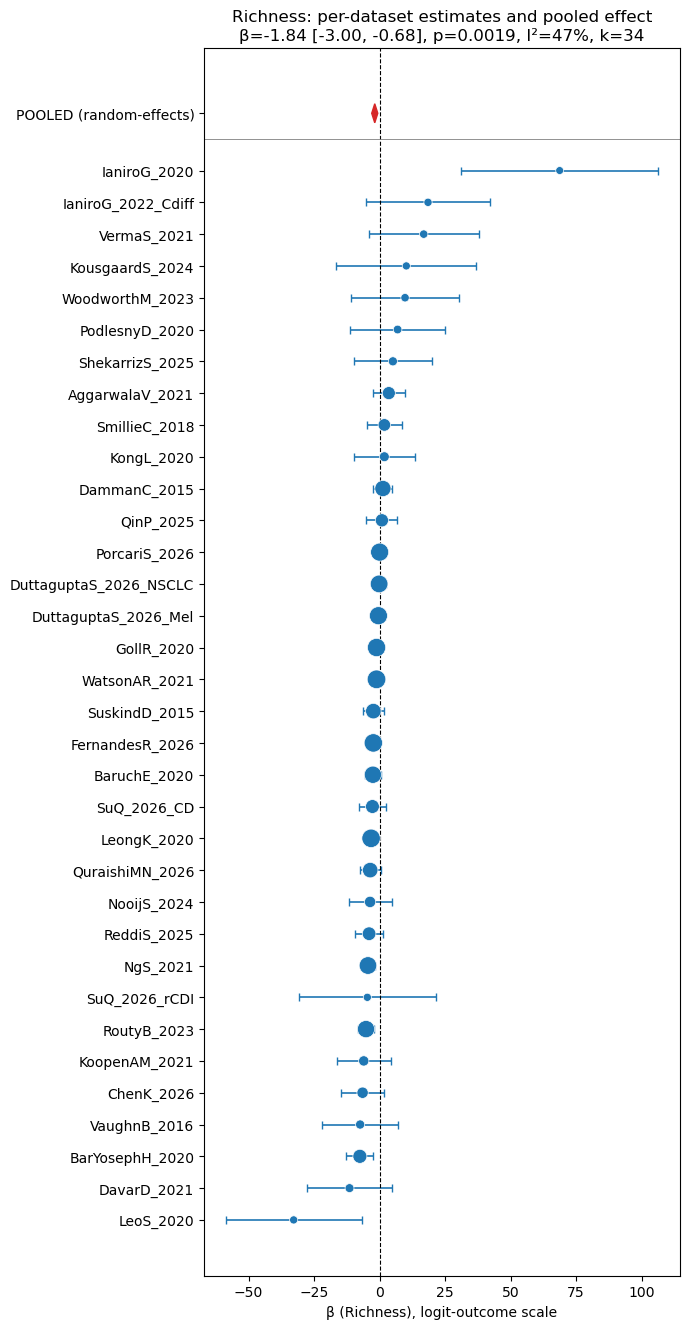

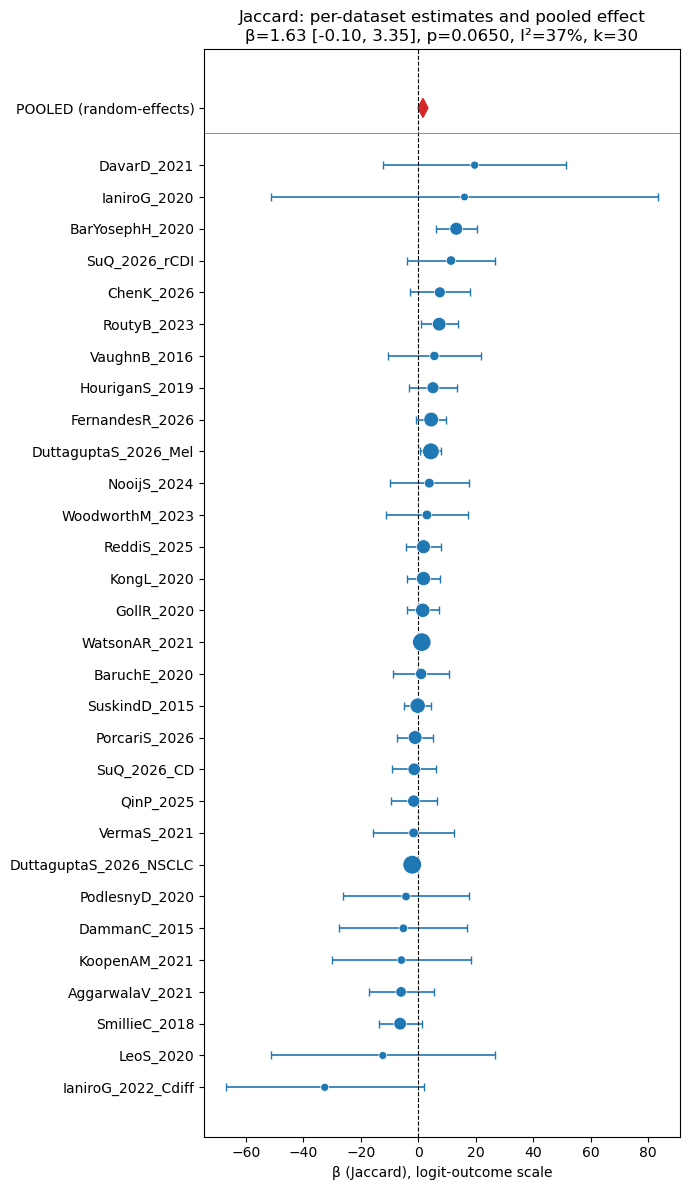

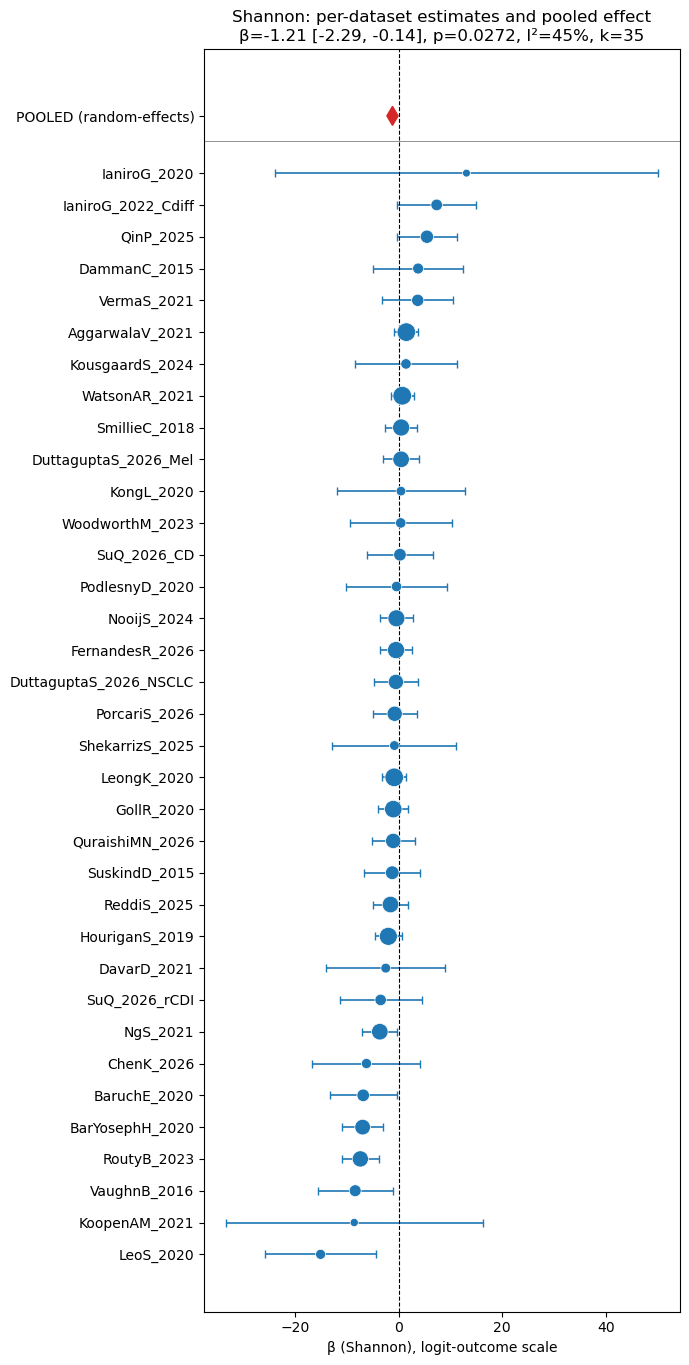

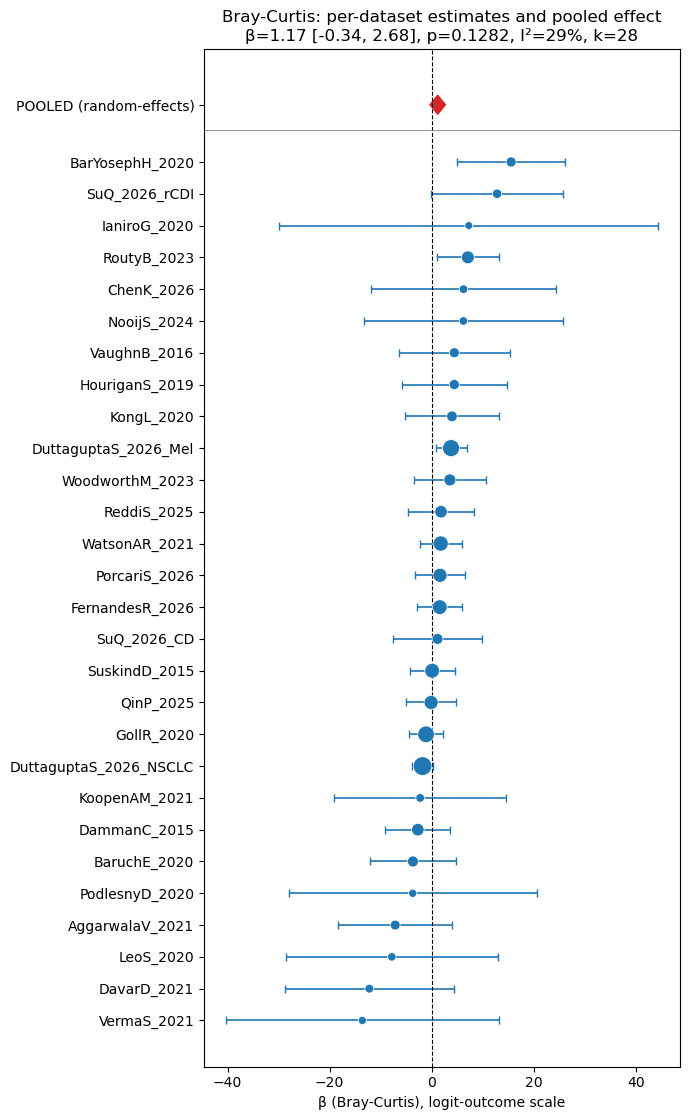

In [26]:
forest_plot(rich_weighted, rich_summary, 'Richness')
forest_plot(jac_weighted, jac_summary, 'Jaccard')
forest_plot(shan_weighted, shan_summary, 'Shannon')
forest_plot(bc_weighted,   bc_summary,   'Bray-Curtis')

## 4. Super-donor hypothesis: donor richness → proportion of donor strains acquired

Primary question #2. Same two-stage design, different outcome (`prop_donor_acquired_logit`) and predictor (`donor_richness_scaled`).

In [27]:
donor_rich_stage1 = fit_per_dataset(
    df, 'donor_richness_scaled', outcome='prop_donor_acquired_logit',
    min_n=6, min_unique=6, unique_col='donor_id')
donor_rich_summary, donor_rich_weighted = dl_meta_analysis(donor_rich_stage1)
print_summary('Donor richness → proportion of donor strains acquired', donor_rich_summary)
display(donor_rich_stage1.round(5))

# ════════════════════════════════════════════════════════════════════
# 4. Donor Shannon -> proportion of donor strains acquired
# ════════════════════════════════════════════════════════════════════
donor_shan_stage1 = fit_per_dataset(
    df, 'donor_shannon_scaled', outcome='prop_donor_acquired_logit',
    min_n=6, min_unique=6, unique_col='donor_id')
donor_shan_summary, donor_shan_weighted = dl_meta_analysis(donor_shan_stage1)
print_summary('Donor Shannon → proportion of donor strains acquired', donor_shan_summary)
display(donor_shan_stage1.round(5))

donor_richness_scaled: 20 of 43 datasets used ({'n<6': 13, 'unique donor_id<6': 10})

Donor richness → proportion of donor strains acquired: pooled β = 1.744 (95% CI 0.487 to 3.002), p = 0.0065, k = 20 datasets
  Heterogeneity: I² = 47%, tau² = 2.951, Q(19) = 35.9, p = 0.011


,n,n_unique,beta,se,p,skipped
study_id,,,,,,
AggarwalaV_2021,9,5,NaN,NaN,NaN,unique donor_id<6
BarYosephH_2020,7,4,NaN,NaN,NaN,unique donor_id<6
BaruchE_2020,10,2,NaN,NaN,NaN,unique donor_id<6
ChenK_2026,11,4,NaN,NaN,NaN,unique donor_id<6
DammanC_2015,6,5,NaN,NaN,NaN,unique donor_id<6
DavarD_2021,13,10,6.78433,4.67865,0.17495,NaN
DuttaguptaS_2026_Mel,19,16,2.98771,1.55324,0.07133,NaN
DuttaguptaS_2026_NSCLC,18,16,4.53042,1.96392,0.03478,NaN
FernandesR_2026,19,19,0.66422,2.57686,0.79968,NaN


donor_shannon_scaled: 20 of 43 datasets used ({'n<6': 13, 'unique donor_id<6': 10})

Donor Shannon → proportion of donor strains acquired: pooled β = 0.545 (95% CI -0.765 to 1.854), p = 0.4150, k = 20 datasets
  Heterogeneity: I² = 63%, tau² = 4.164, Q(19) = 51.1, p = 0.000


,n,n_unique,beta,se,p,skipped
study_id,,,,,,
AggarwalaV_2021,9,5,NaN,NaN,NaN,unique donor_id<6
BarYosephH_2020,7,4,NaN,NaN,NaN,unique donor_id<6
BaruchE_2020,10,2,NaN,NaN,NaN,unique donor_id<6
ChenK_2026,11,4,NaN,NaN,NaN,unique donor_id<6
DammanC_2015,6,5,NaN,NaN,NaN,unique donor_id<6
DavarD_2021,13,10,6.14707,2.78848,0.04970,NaN
DuttaguptaS_2026_Mel,19,16,0.51445,0.95115,0.59561,NaN
DuttaguptaS_2026_NSCLC,18,16,2.83207,2.62094,0.29591,NaN
FernandesR_2026,19,19,0.13001,1.19152,0.91439,NaN


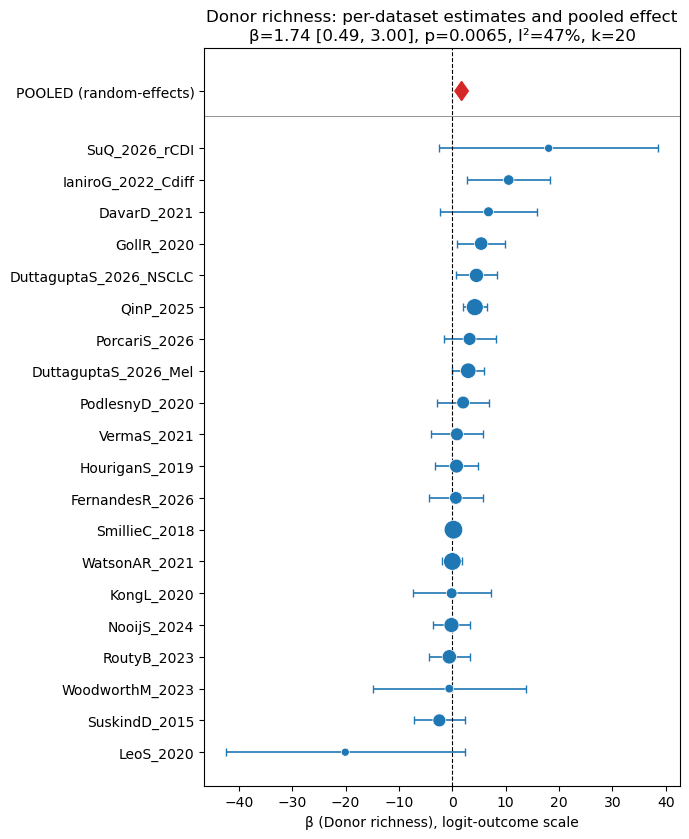

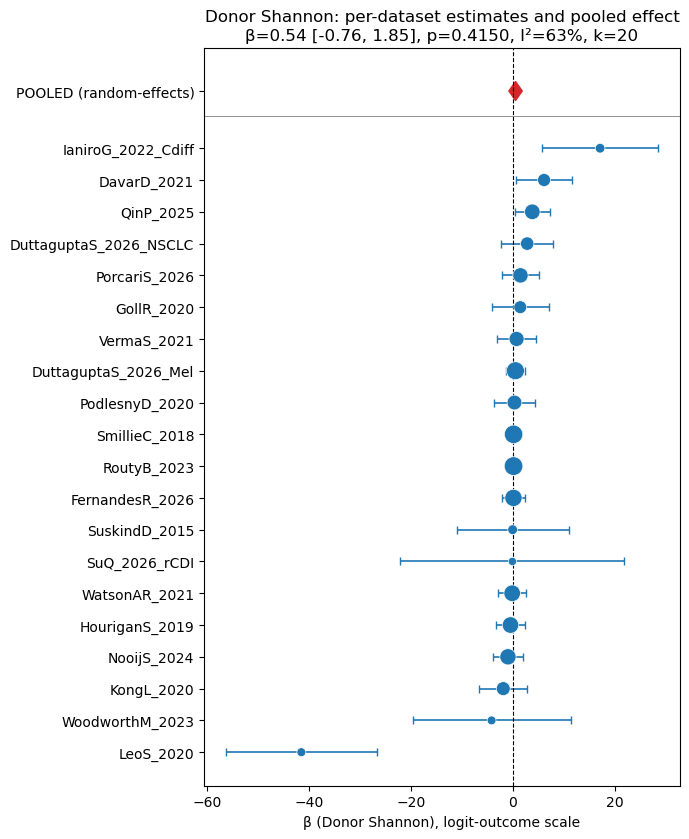

In [28]:
forest_plot(donor_rich_weighted, donor_rich_summary, 'Donor richness')
forest_plot(donor_shan_weighted, donor_shan_summary, 'Donor Shannon')

## 5. Route & bowel prep, restricted to within-study heterogeneity (new)

Route and bowel prep are usually a fixed property of a *study's protocol*, not something that varies triad-to-triad, so a naive across-dataset comparison (Section 6) is confounded with everything else that differs between studies. This section instead asks a within-study question, and gets the answer "for free" from the Section 2 engine:

- Recode the categorical variable as a 0/1 dummy.
- Run `fit_per_dataset(..., min_range=1.0)`. Because a 0/1 variable's range is 0 unless *both* categories are present, this **automatically restricts the analysis to datasets that actually contain both arms** — i.e., exactly the datasets with within-study heterogeneity in that variable — and gives each of those studies its own within-study estimate.
- Pool with the same DL random-effects meta-analysis as everywhere else.

Route is restricted to `upper` vs `lower` (the `both` category is dropped for this contrast — it isn't a meaningful point on an upper/lower axis and is rare).

In [29]:
# ════════════════════════════════════════════════════════════════════
# 5. Within-study comparisons of procedural variables (exploratory)
#    Per dataset: n, median [IQR] per arm, HL shift, rank-biserial, MWU p
# ════════════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

OUTCOME     = 'doser'     # <- adjust to your outcome column
DATASET_COL = 'display_dataset'   # <- adjust to your study/cohort column
MIN_ARM     = 5           # min samples per arm for a p-value to be reported

def _q(x):
    return f'{np.median(x):.3f} [{np.percentile(x, 25):.3f}-{np.percentile(x, 75):.3f}]'

def within_study_compare(data, group_col, ref, other, outcome=OUTCOME,
                         dataset_col=DATASET_COL, min_arm=MIN_ARM, label=None):
    """Compare `other` vs `ref` inside each dataset that has both arms.
    Effect direction: positive HL shift / rank-biserial = higher in `other`."""
    label = label or group_col
    rows = []
    for ds, g in data.groupby(dataset_col):
        a = g.loc[g[group_col] == ref,   outcome].dropna().to_numpy()
        b = g.loc[g[group_col] == other, outcome].dropna().to_numpy()
        if len(a) == 0 or len(b) == 0:
            continue                                   # not a within-study contrast
        row = {
            'dataset': ds,
            f'n_{ref}': len(a), f'n_{other}': len(b),
            f'median_{ref} [IQR]': _q(a),
            f'median_{other} [IQR]': _q(b),
            'median_diff': np.median(b) - np.median(a),
            'HL_shift': np.median(np.subtract.outer(b, a)),
            'rank_biserial': np.nan, 'p': np.nan,
            'tested': len(a) >= min_arm and len(b) >= min_arm,
        }
        if row['tested']:
            u = mannwhitneyu(b, a, alternative='two-sided')
            row['p'] = u.pvalue
            row['rank_biserial'] = 2 * u.statistic / (len(a) * len(b)) - 1
        rows.append(row)

    out = pd.DataFrame(rows)
    print(f'\n=== {label}: {other} vs {ref} (within-study) ===')
    if out.empty:
        print('No dataset has both arms represented.')
        return out
    print(f'{len(out)} dataset(s) with both arms; '
          f'{int(out["tested"].sum())} with >= {min_arm} samples per arm (p reported).')
    display(out.round(3))
    return out

# ── 5a. Route of administration (lower vs upper) ───────────────────
route_sub = df[df['route_binary'].isin(['upper', 'lower'])].copy()
route_within = within_study_compare(route_sub, 'route_binary',
                                    ref='upper', other='lower',
                                    label='Route of administration')

# ── 5b. Bowel preparation (yes vs no) ──────────────────────────────
def _prep_bool(x):
    """'no' -> False; any other non-blank value -> True; blank -> NaN (excluded)."""
    if pd.isna(x) or str(x).strip() == '':
        return np.nan
    return False if str(x).strip().lower() == 'no' else True

df['bowel_prep_bool'] = df['bowel_prep'].apply(_prep_bool)
prep_sub = df.dropna(subset=['bowel_prep_bool']).copy()
prep_within = within_study_compare(prep_sub, 'bowel_prep_bool',
                                   ref=False, other=True,
                                   label='Bowel preparation')

# ── 5c. Stool type (frozen vs fresh) ───────────────────────────────
stool_sub = df[df['fresh_frozen'].isin(['fresh', 'frozen'])].copy()   # <- adjust column name
stool_within = within_study_compare(stool_sub, 'fresh_frozen',
                                    ref='fresh', other='frozen',
                                    label='Stool type')


=== Route of administration: lower vs upper (within-study) ===
2 dataset(s) with both arms; 2 with >= 5 samples per arm (p reported).


,dataset,n_upper,n_lower,median_upper [IQR],median_lower [IQR],median_diff,HL_shift,rank_biserial,p,tested
0,SmillieC_2018,10,6,0.260 [0.185-0.403],0.332 [0.257-0.412],0.072,0.046,0.2,0.562,True
1,WatsonAR_2021,5,5,0.550 [0.480-0.578],0.430 [0.407-0.452],-0.119,-0.102,-0.6,0.151,True



=== Bowel preparation: True vs False (within-study) ===
2 dataset(s) with both arms; 1 with >= 5 samples per arm (p reported).


,dataset,n_False,n_True,median_False [IQR],median_True [IQR],median_diff,HL_shift,rank_biserial,p,tested
0,SmillieC_2018,10,6,0.260 [0.185-0.403],0.332 [0.257-0.412],0.072,0.046,0.2,0.562,True
1,WatsonAR_2021,4,6,0.515 [0.454-0.557],0.441 [0.412-0.509],-0.073,-0.050,NaN,NaN,False



=== Stool type: frozen vs fresh (within-study) ===
2 dataset(s) with both arms; 1 with >= 5 samples per arm (p reported).


,dataset,n_fresh,n_frozen,median_fresh [IQR],median_frozen [IQR],median_diff,HL_shift,rank_biserial,p,tested
0,GollR_2020,12,8,0.160 [0.125-0.261],0.234 [0.185-0.282],0.075,0.060,0.406,0.142,True
1,HouriganS_2019,3,5,0.333 [0.315-0.433],0.389 [0.310-0.412],0.056,0.012,NaN,NaN,False


## 6. Exploratory, across all datasets (descriptive only, not dataset-adjusted)

Everything below pools triads across all 46 datasets and is **not** adjusted for dataset — unlike Sections 3–5, these comparisons *are* confounded with whatever else differs between studies (indication, sequencing depth, protocol...). Treat this as hypothesis-generating: a pattern here is a reason to look closer with the within-study machinery above (where the data support it), not a standalone conclusion.

One shared helper (`styled_boxplot_panel`) draws a single significance-colored panel (Mann-Whitney U vs. a reference group); `exploratory_boxplot` wraps it as one panel, `faceted_boxplot` repeats it once per disease category.

In [30]:
# ════════════════════════════════════════════════════════════════════
# 6a. Disease indication map + a couple more procedural variables
# ════════════════════════════════════════════════════════════════════
indication_map = {
    'AggarwalaV_2021': 'CDiff', 'HouriganS_2019': 'CDiff', 'IaniroG_2022_Cdiff': 'CDiff',
    'KumarR_2017': 'CDiff', 'MossE_2017': 'CDiff', 'NooijS_2024': 'CDiff',
    'PodlesnyD_2020': 'CDiff', 'SmillieC_2018': 'CDiff', 'VermaS_2021': 'CDiff',
    'WatsonAR_2021': 'CDiff', 'SchmidtT_2022_rCDI': 'CDiff', 'SuQ_2026_rCDI': 'CDiff',
    'BaruchE_2020': 'Cancer', 'CM_MORELIA': 'Cancer', 'DavarD_2021': 'Cancer',
    'RoutyB_2023': 'Cancer', 'DuttaguptaS_2026_NSCLC': 'Cancer', 'DuttaguptaS_2026_Mel': 'Cancer',
    'PorcariS_2026': 'Cancer', 'ChenK_2026': 'Cancer', 'FernandesR_2026': 'Cancer',
    'BarYosephH_2020': 'MDRB', 'LeoS_2020': 'MDRB', 'WoodworthM_2023': 'MDRB',
    'IaniroG_2022_MDRB': 'MDRB', 'SinghR_2018': 'MDRB',
    'OrbergET_2025': 'GvHD', 'ReddiS_2025': 'GvHD',
    'LeongK_2020': 'Metabolic disorder', 'KoopenAM_2021': 'Metabolic disorder',
    'LiS_2016': 'Metabolic disorder', 'NgS_2021': 'Metabolic disorder',
    'DammanC_2015': 'IBD (UC)', 'NusbaumD_2018': 'IBD (UC)', 'ShekarrizS_2025': 'IBD (UC)',
    'IaniroG_2022_IBD': 'IBD (UC)', 'LeeS_2017': 'IBD (UC)', 'QuraishiMN_2026': 'IBD (UC)',
    'RossenN_2015': 'IBD (UC)', 'SchmidtT_2022_UC': 'IBD (UC)', 'KousgaardS_2024': 'IBD (UC)',
    'KongL_2020': 'IBD (CD)', 'SuskindD_2015': 'IBD (CD)', 'VaughnB_2016': 'IBD (CD)',
    'SuQ_2026_CD': 'IBD (CD)',
    'GollR_2020': 'IBS', 'IaniroG_2020': 'TKI induced diarrhea',
    'GoloshchapovO_2019': 'Healthy Microbiome', 'QinP_2025': 'Psoriatic arthritis',
    'ZhaoH_2020': 'Tourettes', 'YanJ_2024': 'ALS',
}
df['indication_clean'] = df['display_dataset'].map(indication_map)
df['disease_category'] = df['indication_clean'].map(
    lambda x: 'Infectious' if x in ('CDiff', 'MDRB') else ('Non-infectious' if pd.notna(x) else np.nan)
)
df['stool_frozen_label'] = df['fresh_frozen'].str.lower().str.strip()

print('indication_clean:', df['indication_clean'].value_counts(dropna=False).to_dict())
print('disease_category:', df['disease_category'].value_counts(dropna=False).to_dict())
print('\nCross-tab, route × disease category:')
display(pd.crosstab(df['route_binary'], df['disease_category'], dropna=False))
print('\nCross-tab, bowel prep × disease category:')
display(pd.crosstab(df['bowel_prep_bool'], df['disease_category'], dropna=False))

indication_clean: {'CDiff': 172, 'Cancer': 129, 'Metabolic disorder': 92, 'IBD (CD)': 54, 'IBD (UC)': 52, 'MDRB': 34, 'IBS': 20, 'GvHD': 17, 'Psoriatic arthritis': 12, 'TKI induced diarrhea': 6, 'Tourettes': 5, 'Healthy Microbiome': 3, 'ALS': 2}
disease_category: {'Non-infectious': 392, 'Infectious': 206}

Cross-tab, route × disease category:


disease_category,Infectious,Non-infectious
route_binary,,
both,28,16
lower,108,113
upper,46,222
NaN,24,41



Cross-tab, bowel prep × disease category:


disease_category,Infectious,Non-infectious
bowel_prep_bool,,
NaN,23,85
False,40,141
True,143,166


In [31]:
# ════════════════════════════════════════════════════════════════════
# 6b. Shared boxplot helpers (significance-colored vs. a reference group)
# ════════════════════════════════════════════════════════════════════
NONSIG_COLOR = '#BBBBBB'


def sig_color(p):
    if pd.isna(p):
        return NONSIG_COLOR
    if p < 0.001:
        return '#4B0082'
    if p < 0.01:
        return '#0072B2'
    if p < 0.05:
        return '#009E73'
    return NONSIG_COLOR


SIG_LEGEND = [
    mlines.Line2D([0], [0], marker='s', color='w', markerfacecolor='#4B0082', markersize=10, label='p < 0.001'),
    mlines.Line2D([0], [0], marker='s', color='w', markerfacecolor='#0072B2', markersize=10, label='p < 0.01'),
    mlines.Line2D([0], [0], marker='s', color='w', markerfacecolor='#009E73', markersize=10, label='p < 0.05'),
    mlines.Line2D([0], [0], marker='s', color='w', markerfacecolor=NONSIG_COLOR, markersize=10, label='p ≥ 0.05 / ref'),
]


def styled_boxplot_panel(ax, d, col, outcome, order, reference, min_n=5):
    """Draw one significance-colored boxplot panel (Mann-Whitney vs `reference`) onto `ax`."""
    counts = d[col].value_counts()
    panel_order = [c for c in order if c in counts.index and counts[c] >= min_n]

    if reference not in panel_order or len(panel_order) < 2:
        ax.set_title('(insufficient data)', fontsize=10)
        ax.axis('off')
        return

    groups = {c: d.loc[d[col] == c, outcome].values for c in panel_order}
    ref_vals = groups[reference]

    pvals = {}
    for c in panel_order:
        pvals[c] = np.nan if c == reference else stats.mannwhitneyu(
            groups[c], ref_vals, alternative='two-sided')[1]

    colors = [NONSIG_COLOR if c == reference else sig_color(pvals[c]) for c in panel_order]

    bp = ax.boxplot([groups[c] for c in panel_order], patch_artist=True, showmeans=True,
                     medianprops=dict(color='black'), tick_labels=[str(c) for c in panel_order])
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.55)

    for i, c in enumerate(panel_order):
        jitter = np.random.normal(0, 0.05, size=len(groups[c]))
        ax.scatter(np.full(len(groups[c]), i + 1) + jitter, groups[c],
                   alpha=0.45, s=14, color='black', zorder=3)

    ymax = d[outcome].max()
    for i, c in enumerate(panel_order):
        label = f'ref (n={counts[c]})' if c == reference else f'p={pvals[c]:.3f} (n={counts[c]})'
        weight = 'bold' if (not pd.isna(pvals[c]) and pvals[c] < 0.05) else 'normal'
        ax.text(i + 1, ymax * 1.06, label, ha='center', va='bottom', fontsize=8.5, fontweight=weight)

    ax.set_ylim(top=ymax * 1.18)


def exploratory_boxplot(df, col, title, order, reference, outcome='engraftment_rate',
                        min_n=5, filename=None):
    """Single-panel exploratory boxplot across ALL datasets pooled (not adjusted for study)."""
    d = df[[col, outcome]].dropna()
    fig, ax = plt.subplots(figsize=(max(6, 1.3 * len(order)), 5.5))
    styled_boxplot_panel(ax, d, col, outcome, order, reference, min_n=min_n)
    ax.set_ylabel(f'{outcome} (raw)')
    ax.set_title(f'{title}\n(exploratory, between-dataset — not adjusted for study)')
    fig.legend(handles=SIG_LEGEND, title='vs. reference', loc='center left',
              bbox_to_anchor=(1.0, 0.5), fontsize=9, title_fontsize=9,
              frameon=True, fancybox=True, framealpha=1.0, edgecolor='0.6')
    plt.tight_layout()
    fname = filename or f'exploratory_boxplot_{col}.svg'
    plt.savefig(fname, bbox_inches='tight', bbox_extra_artists=(fig.legends[0],))
    plt.show()


def faceted_boxplot(df, col, facet_col, title, order, reference, outcome='engraftment_rate',
                    min_n=5, filename=None):
    """One significance-colored panel per level of `facet_col` (e.g. disease category)."""
    facets = sorted(df[facet_col].dropna().unique())
    fig, axes = plt.subplots(1, len(facets), figsize=(6 * len(facets), 5.5), sharey=True)
    if len(facets) == 1:
        axes = [axes]

    for ax, facet in zip(axes, facets):
        d = df[df[facet_col] == facet][[col, outcome]].dropna()
        styled_boxplot_panel(ax, d, col, outcome, order, reference, min_n=min_n)
        ax.set_title(f'{facet} (n={len(d)})', fontsize=10.5)

    axes[0].set_ylabel(f'{outcome} (raw)', fontsize=10)
    fig.suptitle(f'{title}\n(exploratory, between-dataset — not adjusted for study)', fontsize=11, y=1.02)
    fig.legend(handles=SIG_LEGEND, title='vs. reference', loc='center left',
              bbox_to_anchor=(1.0, 0.5), fontsize=9, title_fontsize=9,
              frameon=True, fancybox=True, framealpha=1.0, edgecolor='0.6')
    plt.tight_layout()
    fname = filename or f'exploratory_boxplot_{col}_by_{facet_col}.svg'
    plt.savefig(fname, bbox_inches='tight', bbox_extra_artists=(fig.legends[0],))
    plt.show()

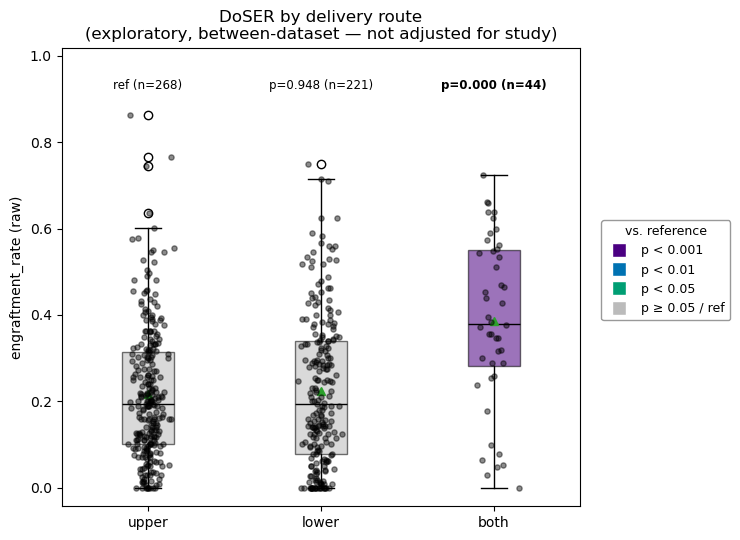

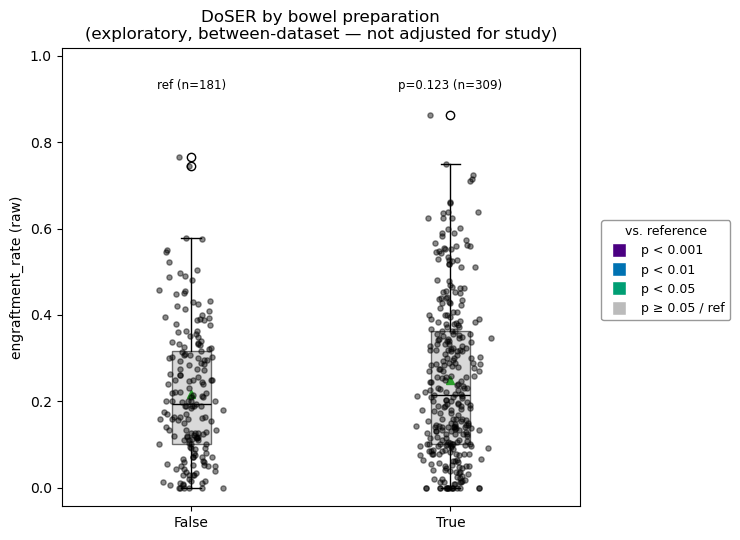

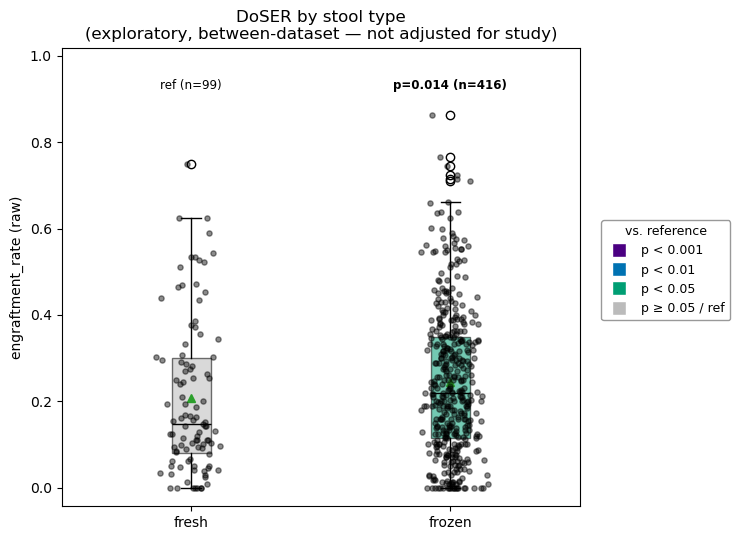

In [32]:
# ════════════════════════════════════════════════════════════════════
# 6c. Overall (not split by disease category)
# ════════════════════════════════════════════════════════════════════
exploratory_boxplot(df, 'route_binary', 'DoSER by delivery route',
                    order=['upper', 'lower', 'both'], reference='upper')

exploratory_boxplot(df, 'bowel_prep_bool', 'DoSER by bowel preparation',
                    order=[False, True], reference=False)

exploratory_boxplot(df, 'stool_frozen_label', 'DoSER by stool type',
                    order=['fresh', 'frozen'], reference='fresh')

In [33]:
def print_comparison(df, col, title, order, reference, outcome='engraftment_rate',
                     min_n=5, facet_col=None):
    """Print Mann-Whitney U results vs `reference` (same logic as the boxplots)."""
    def _one(d, label):
        counts = d[col].value_counts()
        panel_order = [c for c in order if c in counts.index and counts[c] >= min_n]
        print(f'\n{title}{label}')
        if reference not in panel_order or len(panel_order) < 2:
            print('  (insufficient data)')
            return
        groups = {c: d.loc[d[col] == c, outcome].values for c in panel_order}
        ref = groups[reference]
        rows = []
        for c in panel_order:
            g = groups[c]
            q1, med, q3 = np.percentile(g, [25, 50, 75])
            row = dict(group=str(c), n=len(g), median=med, IQR=f'{q1:.3f}-{q3:.3f}',
                       mean=g.mean(), p=np.nan, rank_biserial=np.nan)
            if c != reference:
                u, p = stats.mannwhitneyu(g, ref, alternative='two-sided')
                row['p'] = p
                row['rank_biserial'] = 2 * u / (len(g) * len(ref)) - 1  # >0: group higher than ref
            rows.append(row)
        out = pd.DataFrame(rows)
        out['p'] = out['p'].map(lambda x: 'ref' if pd.isna(x) else f'{x:.10g}')
        print(out.to_string(index=False, float_format=lambda x: f'{x:.3f}'))
        print(f'  (Mann-Whitney U, two-sided, vs "{reference}"; unadjusted for study)')

    if facet_col is None:
        _one(df[[col, outcome]].dropna(), '')
    else:
        for facet in sorted(df[facet_col].dropna().unique()):
            d = df[df[facet_col] == facet][[col, outcome]].dropna()
            _one(d, f' — {facet} (n={len(d)})')


# 6c. Overall
print_comparison(df, 'route_binary', 'DoSER by delivery route',
                 order=['upper', 'lower', 'both'], reference='upper')

print_comparison(df, 'bowel_prep_bool', 'DoSER by bowel preparation',
                 order=[False, True], reference=False)

print_comparison(df, 'stool_frozen_label', 'DoSER by stool type',
                 order=['fresh', 'frozen'], reference='fresh')


DoSER by delivery route
group   n  median         IQR  mean               p  rank_biserial
upper 268   0.194 0.100-0.314 0.217             ref            NaN
lower 221   0.194 0.079-0.340 0.224    0.9479554396          0.003
 both  44   0.380 0.282-0.550 0.386 1.477531932e-07          0.494
  (Mann-Whitney U, two-sided, vs "upper"; unadjusted for study)

DoSER by bowel preparation
group   n  median         IQR  mean           p  rank_biserial
False 181   0.193 0.100-0.317 0.217         ref            NaN
 True 309   0.215 0.101-0.364 0.249 0.123322715          0.083
  (Mann-Whitney U, two-sided, vs "False"; unadjusted for study)

DoSER by stool type
 group   n  median         IQR  mean             p  rank_biserial
 fresh  99   0.147 0.081-0.299 0.207           ref            NaN
frozen 416   0.219 0.115-0.348 0.244 0.01425870442          0.158
  (Mann-Whitney U, two-sided, vs "fresh"; unadjusted for study)


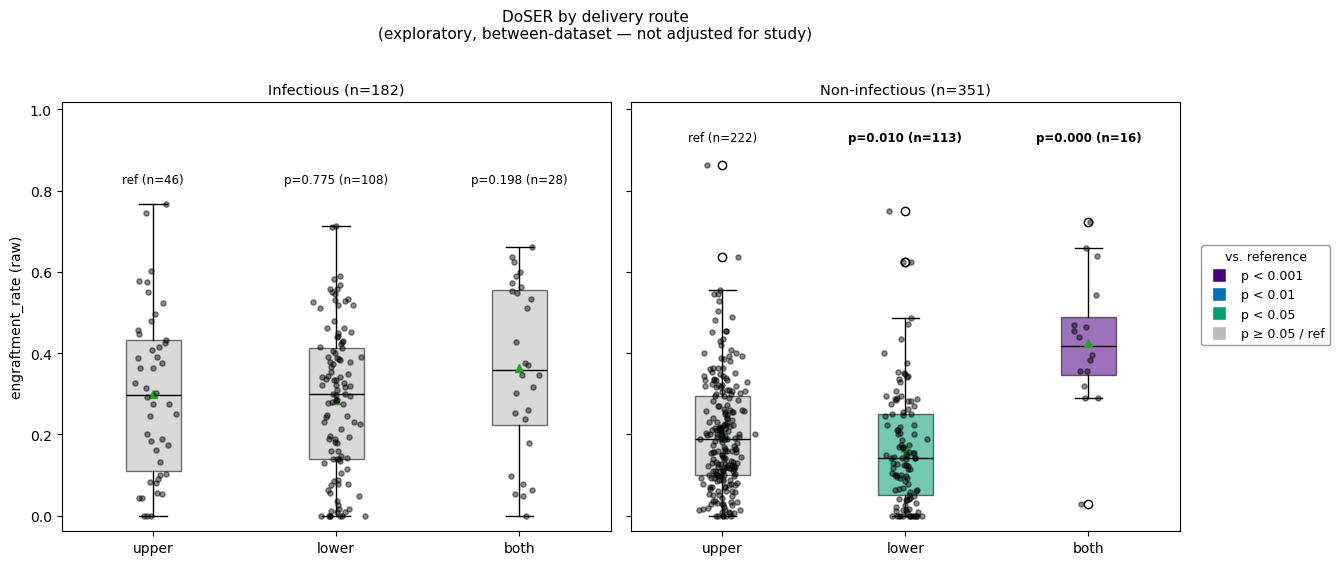

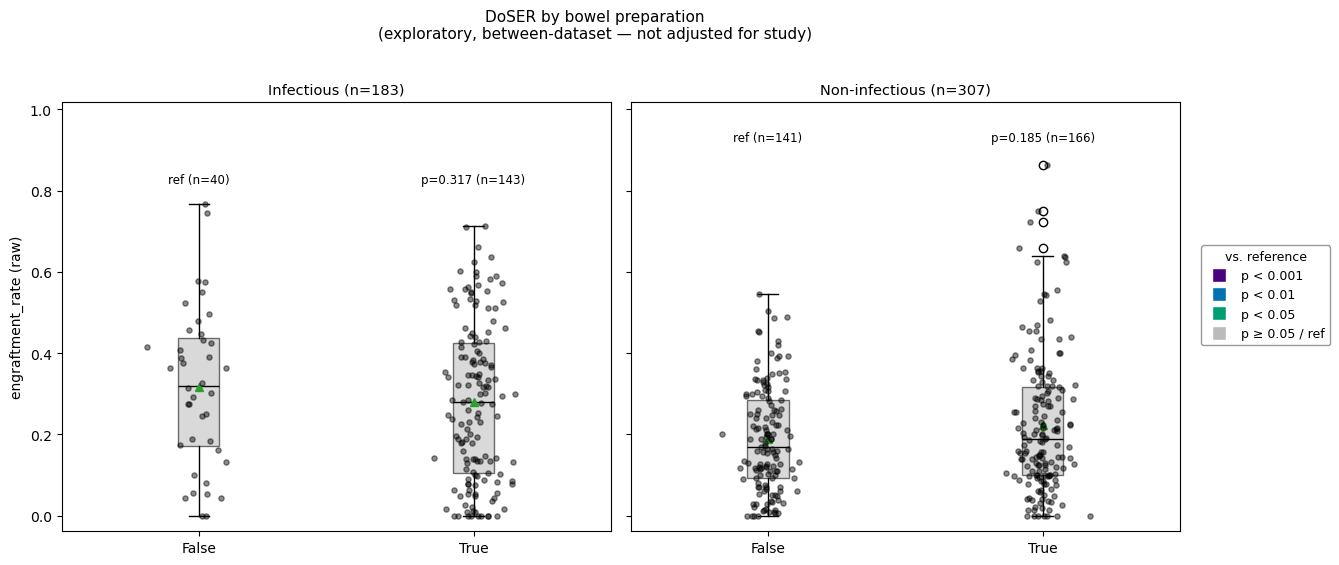

In [34]:
# ════════════════════════════════════════════════════════════════════
# 6d. Split by disease category (infectious vs non-infectious)
# ════════════════════════════════════════════════════════════════════
faceted_boxplot(
    df, 'route_binary', 'disease_category', 'DoSER by delivery route',
    order=['upper', 'lower', 'both'], reference='upper'
)

faceted_boxplot(
    df, 'bowel_prep_bool', 'disease_category', 'DoSER by bowel preparation',
    order=[False, True], reference=False
)

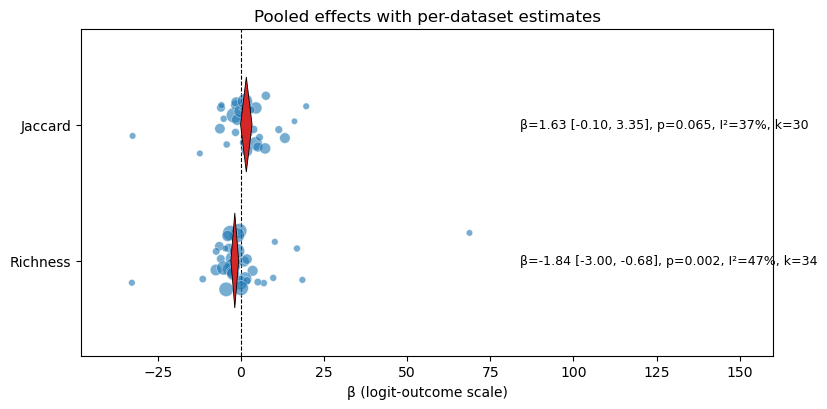

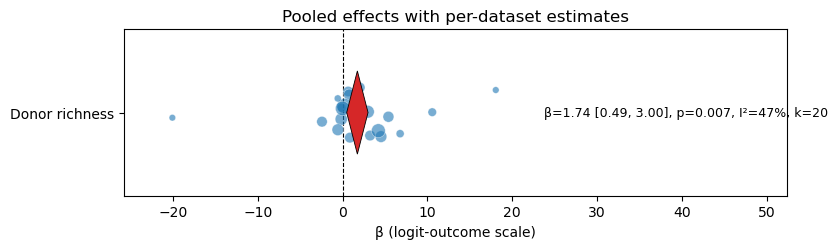

,k (datasets),beta_pooled,ci_lo,ci_hi,p_pooled,I2 (%),tau2,Q,df_Q,p_Q (heterogeneity)
comparison,,,,,,,,,,
Richness → DoSER,34,-1.841,-3.001,-0.681,0.001872,47.2,4.024,62.47,33,0.001453
Jaccard → DoSER,30,1.625,-0.101,3.352,0.065004,36.9,6.080,45.94,29,0.023811
Donor richness → prop. donor acquired,20,1.744,0.487,3.002,0.006540,47.1,2.951,35.95,19,0.010714


In [35]:
def combined_forest_plot(entries, filename='forest_combined.svg', annotate=True):
    """
    entries: list of (label, weighted_df, summary) tuples from dl_meta_analysis().
    One row per entry: pooled diamond + jittered per-dataset points (sized by
    weight). If annotate=True, prints beta/CI/p/I2/k to the right of each row.
    """
    fig, ax = plt.subplots(figsize=(8.5, 1.6 * len(entries) + 1))
    row_height = 1.0
    xmax = max(weighted['beta'].max() for _, weighted, _ in entries)
    xmin = min(weighted['beta'].min() for _, weighted, _ in entries)
    xpad = 0.15 * (xmax - xmin if xmax > xmin else 1)

    for i, (label, weighted, summary) in enumerate(entries):
        y0 = i * row_height

        jitter = np.random.uniform(-0.22, 0.22, size=len(weighted))
        sizes = 20 + 100 * (weighted['weight_re_pct'] / weighted['weight_re_pct'].max())
        ax.scatter(weighted['beta'], y0 + jitter, s=sizes, color='#1f77b4',
                  alpha=0.6, edgecolor='white', linewidth=0.4, zorder=2)

        dx = [summary['ci_lo'], summary['beta_pooled'], summary['ci_hi'], summary['beta_pooled']]
        dy = [y0, y0 + 0.35, y0, y0 - 0.35]
        ax.fill(dx, dy, color='#d62728', zorder=3, edgecolor='black', linewidth=0.6)

        if annotate:
            p = summary['p_pooled']
            p_txt = 'p<0.001' if p < 0.001 else f'p={p:.3f}'
            ax.text(xmax + xpad, y0,
                    f'β={summary["beta_pooled"]:.2f} [{summary["ci_lo"]:.2f}, {summary["ci_hi"]:.2f}], '
                    f'{p_txt}, I²={summary["I2"]:.0f}%, k={summary["k"]}',
                    va='center', ha='left', fontsize=9)

    ax.axvline(0, color='black', lw=0.8, linestyle='--', zorder=1)
    ax.set_yticks([i * row_height for i in range(len(entries))])
    ax.set_yticklabels([e[0] for e in entries])
    ax.set_ylim(-0.7, (len(entries) - 1) * row_height + 0.7)
    if annotate:
        ax.set_xlim(xmin - xpad, xmax + xpad * 6)  # leave room for the annotation text
    ax.set_xlabel('β (logit-outcome scale)')
    ax.set_title('Pooled effects with per-dataset estimates')
    plt.tight_layout()
    plt.savefig(filename, bbox_inches='tight')
    plt.show()


# Richness + Jaccard, side by side
combined_forest_plot([
    ('Richness', rich_weighted, rich_summary),
    ('Jaccard',  jac_weighted,  jac_summary),
], filename='forest_richness_jaccard.svg')

# Donor richness -> proportion of donor strains acquired, on its own
combined_forest_plot([
    ('Donor richness', donor_rich_weighted, donor_rich_summary),
], filename='forest_donor_richness.svg')


# ── Summary table ──────────────────────────────────────────────
def summary_table(entries):
    rows = []
    for label, weighted, summary in entries:
        rows.append({
            'comparison': label,
            'k (datasets)': summary['k'],
            'beta_pooled': round(summary['beta_pooled'], 3),
            'ci_lo': round(summary['ci_lo'], 3),
            'ci_hi': round(summary['ci_hi'], 3),
            'p_pooled': summary['p_pooled'],
            'I2 (%)': round(summary['I2'], 1),
            'tau2': round(summary['tau2'], 3),
            'Q': round(summary['Q'], 2),
            'df_Q': summary['df_Q'],
            'p_Q (heterogeneity)': summary['p_Q'],
        })
    return pd.DataFrame(rows).set_index('comparison')


results_table = summary_table([
    ('Richness → DoSER', rich_weighted, rich_summary),
    ('Jaccard → DoSER', jac_weighted, jac_summary),
    ('Donor richness → prop. donor acquired', donor_rich_weighted, donor_rich_summary),
])
results_table

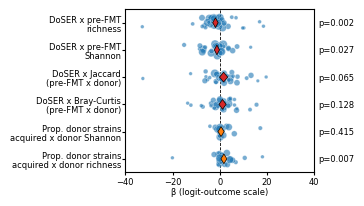

In [36]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'

MM = 1 / 25.4  # mm -> inches

# ── Easy-to-edit default palette ───────────────────────────────
POINT_COLOR   = '#1f77b4'
POINT_ALPHA   = 0.6
DIAMOND_COLOR = '#d62728'
DIAMOND_EDGE  = 'black'
# ───────────────────────────────────────────────────────────────

# ── Fixed layout in mm (shared by all forest plots so they align) ──
LEFT_MM   = 30
RIGHT_MM  = 12
BOTTOM_MM = 7
TOP_MM    = 1.5
ROW_MM    = 12
# ───────────────────────────────────────────────────────────────


def combined_forest_plot(entries, filename='forest_combined.svg', annotate=True,
                         xlim=(-40, 40), fig_mm=None,
                         diamond_half_height=0.18,
                         point_color=None, diamond_color=None,
                         diamond_edge=None, point_alpha=None):
    """
    entries: list of (label, weighted_df, summary) tuples, OR
             (label, weighted_df, summary, style_overrides) tuples, where
             style_overrides is a dict that can set 'point_color',
             'diamond_color', 'diamond_edge', 'point_alpha' for just that row.
    """
    point_color   = point_color   or POINT_COLOR
    diamond_color = diamond_color or DIAMOND_COLOR
    diamond_edge  = diamond_edge  or DIAMOND_EDGE
    point_alpha   = POINT_ALPHA if point_alpha is None else point_alpha

    # normalize entries to always have a style dict (empty = use plot defaults)
    norm_entries = []
    for e in entries:
        if len(e) == 4:
            label, weighted, summary, style = e
        else:
            label, weighted, summary = e
            style = {}
        norm_entries.append((label, weighted, summary, style))

    

    if fig_mm is None:
        W = 90
        H = TOP_MM + BOTTOM_MM + len(norm_entries) * ROW_MM
        row_mm = ROW_MM
    else:
        W, H = fig_mm
        row_mm = (H - BOTTOM_MM - TOP_MM) / len(norm_entries)  # rows fill the height
        
    fig = plt.figure(figsize=(W * MM, H * MM))
    ax = fig.add_axes([LEFT_MM / W,
                       BOTTOM_MM / H,
                       (W - LEFT_MM - RIGHT_MM) / W,
                       (H - BOTTOM_MM - TOP_MM) / H])

    for i, (label, weighted, summary, style) in enumerate(norm_entries):
        y0 = i * 1.0
        pc = style.get('point_color', point_color)
        dc = style.get('diamond_color', diamond_color)
        de = style.get('diamond_edge', diamond_edge)
        pa = style.get('point_alpha', point_alpha)

        jitter = np.random.uniform(-0.22, 0.22, size=len(weighted))
        sizes = 6 + 30 * (weighted['weight_re_pct'] / weighted['weight_re_pct'].max())
        ax.scatter(weighted['beta'], y0 + jitter, s=sizes, color=pc,
                   alpha=pa, edgecolor='white', linewidth=0.3, zorder=2)

        dx = [summary['ci_lo'], summary['beta_pooled'], summary['ci_hi'], summary['beta_pooled']]
        dy = [y0, y0 + diamond_half_height, y0, y0 - diamond_half_height]
        ax.fill(dx, dy, facecolor=dc, edgecolor=de, linewidth=0.5, zorder=3)

        if annotate:
            p = summary['p_pooled']
            p_txt = 'p<0.001' if p < 0.001 else f'p={p:.3f}'
            ax.text(1.02, y0, p_txt, transform=ax.get_yaxis_transform(),
                    va='center', ha='left', fontsize=6)

    axes_h_mm = H - BOTTOM_MM - TOP_MM
    half_span = axes_h_mm / row_mm / 2
    center = (len(norm_entries) - 1) / 2
    ax.set_ylim(center - half_span, center + half_span)

    ax.axvline(0, color='black', lw=0.6, linestyle='--', zorder=1)
    ax.set_xlim(*xlim)
    ax.set_yticks(range(len(norm_entries)))
    ax.set_yticklabels([e[0] for e in norm_entries], fontsize=6, linespacing=1.0)
    ax.tick_params(axis='x', labelsize=6, length=2, pad=1)
    ax.tick_params(axis='y', length=2, pad=1)
    ax.set_xlabel('β (logit-outcome scale)', fontsize=6, labelpad=1)

    fig.savefig(filename)
    plt.show()


# All three comparisons on one plot, donor richness diamond in a different color
combined_forest_plot([
    ('Prop. donor strains\nacquired x donor richness',
     donor_rich_weighted, donor_rich_summary,
     {'diamond_color': '#ff7f0e'}),
    ('Prop. donor strains\nacquired x donor Shannon',
     donor_shan_weighted, donor_shan_summary,
     {'diamond_color': '#ff7f0e'}),
    ('DoSER x Bray-Curtis\n(pre-FMT x donor)',
     bc_weighted, bc_summary),
    ('DoSER x Jaccard\n(pre-FMT x donor)',
     jac_weighted, jac_summary),
    ('DoSER x pre-FMT\nShannon',
     shan_weighted, shan_summary),
    ('DoSER x pre-FMT\nrichness',
     rich_weighted, rich_summary),
], filename='forest_all_six.svg', fig_mm=(90, 50))

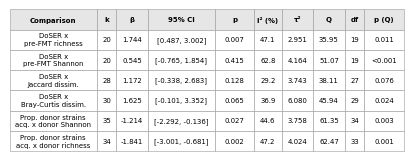

In [46]:
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'

MM = 1 / 25.4

# ── Easy-to-edit table styling ─────────────────────────────────
HEADER_FILL = '#e6e6e6'
HEADER_TEXT = 'black'
BODY_FILL   = 'white'
LINE_COLOR  = '#999999'
FONT_SIZE   = 5
# ───────────────────────────────────────────────────────────────


def _fmt_p(p):
    return '<0.001' if p < 0.001 else f'{p:.3f}'


def summary_table_svg(entries, filename='summary_table.svg', width_mm=100,
                      row_labels=None, row_mm=8.0, max_height_mm=None):
    """
    entries: list of (label, weighted_df, summary) tuples.
    Rows = comparisons, columns = statistics.
    """
    row_labels = row_labels or [e[0] for e in entries]
    sums = [e[2] for e in entries]

    # (header, fraction of total width, formatter) -- fractions sum to 1.0
    cols = [
        ('Comparison',   0.22, None),
        ('k',            0.05, lambda s: f"{s['k']}"),
        ('β',            0.08, lambda s: f"{s['beta_pooled']:.3f}"),
        ('95% CI',       0.17, lambda s: f"[{s['ci_lo']:.3f}, {s['ci_hi']:.3f}]"),
        ('p',            0.10, lambda s: _fmt_p(s['p_pooled'])),
        ('I² (%)',       0.07, lambda s: f"{s['I2']:.1f}"),
        ('τ²',           0.08, lambda s: f"{s['tau2']:.3f}"),
        ('Q',            0.08, lambda s: f"{s['Q']:.2f}"),
        ('df',           0.05, lambda s: f"{s['df_Q']}"),
        ('p (Q)',        0.10, lambda s: _fmt_p(s['p_Q'])),
    ]

    header = [c[0] for c in cols]
    body = [[lab] + [c[2](s) for c in cols[1:]] for lab, s in zip(row_labels, sums)]

    n_rows = len(body) + 1
    if max_height_mm is not None:
        row_mm = min(row_mm, max_height_mm / n_rows)   # shrink rows to fit the cap
    height_mm = n_rows * row_mm
    fig = plt.figure(figsize=(width_mm * MM, height_mm * MM))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.axis('off')

    tbl = ax.table(cellText=body, colLabels=header, cellLoc='center', loc='center')
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(FONT_SIZE)

    xs = [0]
    for _, w, _ in cols:
        xs.append(xs[-1] + w)
    h = 1 / n_rows

    for (r, c), cell in tbl.get_celld().items():
        cell.set_bounds(xs[c], 1 - (r + 1) * h, cols[c][1], h)
        cell.set_edgecolor(LINE_COLOR)
        cell.set_linewidth(0.4)
        cell.set_facecolor(HEADER_FILL if r == 0 else BODY_FILL)
        cell.set_text_props(fontsize=FONT_SIZE)          # <- all cells, header and body
        if r == 0:
            cell.set_text_props(color=HEADER_TEXT, weight='bold')
        if c == 0:
            cell._loc = 'left'
            cell.PAD = 0.04

    fig.savefig(filename)  # no bbox_inches='tight' so width stays exactly 90 mm
    plt.show()

summary_table_svg(
    [
        ('', donor_rich_weighted, donor_rich_summary),
        ('', donor_shan_weighted, donor_shan_summary),
        ('', bc_weighted,         bc_summary),
        ('', jac_weighted,        jac_summary),
        ('', shan_weighted,       shan_summary),
        ('', rich_weighted,       rich_summary),
    ],
    filename='diversity_MA.svg',
    row_mm=5.5,
    max_height_mm=36,
    row_labels=[
    'DoSER x\npre-FMT richness',
    'DoSER x\npre-FMT Shannon',
    'DoSER x\nJaccard dissim.',
    'DoSER x\nBray-Curtis dissim.',
    'Prop. donor strains\nacq. x donor Shannon',
    'Prop. donor strains\nacq. x donor richness',
]
)

Indication: Infectious (n=17, median=57.0) vs Non-infectious (n=31, median=185.0): U=89.5, p=0.0002

Antibiotic exposure (Kruskal-Wallis): H=20.54, p=0.0000, n=3 groups of 48 total
  ABX: n=11, median=57.0
  ABX FMT pretreatment: n=10, median=57.5
  No ABX: n=27, median=194.0

Pairwise Mann-Whitney follow-up:
  ABX vs ABX FMT pretreatment: U=51.0, p=0.8052
  ABX vs No ABX: U=28.0, p=0.0001
  ABX FMT pretreatment vs No ABX: U=38.0, p=0.0010


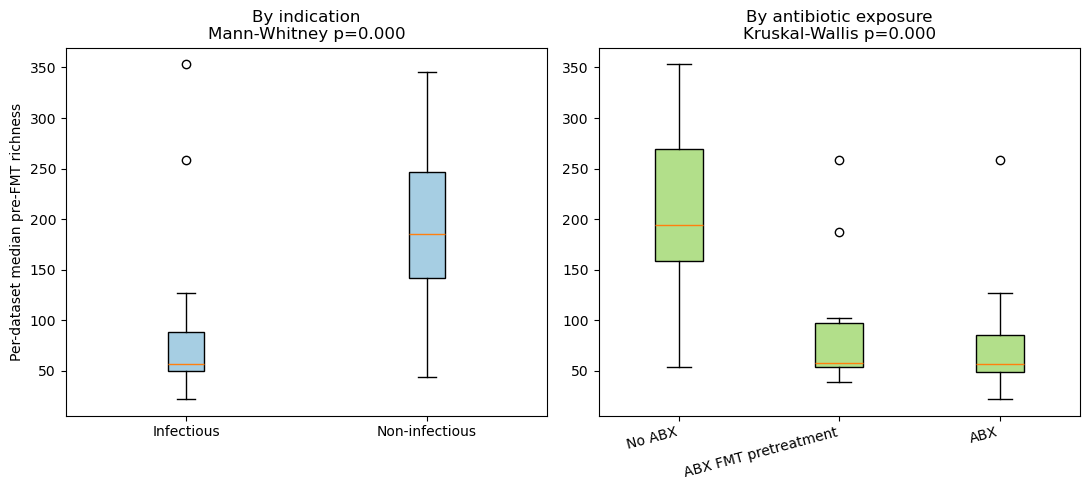

In [38]:
# ============================================================
# Pre-FMT richness by indication / antibiotic-exposure group
# (dataset-level — each STUDY is one observation, matching the
#  design of your original DoSER-by-indication analysis)
# ============================================================
abx_pretreatment_map = {
    # Therapeutic ABX treatment
    'IaniroG_2022_MDRB': 'ABX', 'HouriganS_2019': 'ABX', 'VermaS_2021': 'ABX',
    'MossE_2017': 'ABX', 'PodlesnyD_2020': 'ABX', 'SmillieC_2018': 'ABX',
    'BarYosephH_2020': 'ABX', 'KumarR_2017': 'ABX', 'NooijS_2024': 'ABX', 'KousgaardS_2024': 'ABX', 
    # FMT pre-treatment (part of the FMT procedure)
    'WatsonAR_2021': 'ABX FMT pretreatment', 'LeoS_2020': 'ABX FMT pretreatment',
    'AggarwalaV_2021': 'ABX FMT pretreatment', 'IaniroG_2022_Cdiff': 'ABX FMT pretreatment',
    'BaruchE_2020': 'ABX FMT pretreatment', 'SuskindD_2015': 'ABX FMT pretreatment',
    'WoodworthM_2023': 'ABX FMT pretreatment', 'ReddiS_2025': 'ABX FMT pretreatment',
    'OrbergET_2025': 'ABX FMT pretreatment', 'YanJ_2024': 'ABX FMT pretreatment',
    'SuQ_2026_rCDI': 'ABX FMT pretreatment',
    # No ABX pretreatment
    'IaniroG_2022_IBD': 'No ABX', 'ZhaoH_2020': 'No ABX', 'VaughnB_2016': 'No ABX',
    'DammanC_2015': 'No ABX', 'DavarD_2021': 'No ABX', 'KoopenAM_2021': 'No ABX',
    'KongL_2020': 'No ABX', 'LiS_2016': 'No ABX', 'GollR_2020': 'No ABX',
    'IaniroG_2020': 'No ABX', 'GoloshchapovO_2019': 'No ABX', 'LeongK_2020': 'No ABX',
    'CM_MORELIA': 'No ABX', 'RoutyB_2023': 'No ABX', 'DuttaguptaS_2026_Mel': 'No ABX',
    'DuttaguptaS_2026_NSCLC': 'No ABX', 'NgS_2021': 'No ABX', 'NusbaumD_2018': 'No ABX',
    'QinP_2025': 'No ABX', 'PorcariS_2026': 'No ABX', 'ShekarrizS_2025': 'No ABX',
    'LeeS_2017': 'No ABX', 'QuraishiMN_2026': 'No ABX', 'SuQ_2026_CD': 'No ABX',
    'FernandesR_2026': 'No ABX', 'RossenN_2015': 'No ABX', 'ChenK_2026': 'No ABX',
    'SinghR_2018': 'No ABX', 'SchmidtT_2022_UC': 'No ABX', 'SchmidtT_2022_rCDI': 'ABX',
}
df['abx_group'] = df['display_dataset'].map(abx_pretreatment_map)

# One row per STUDY (median richness within that study), same unit of
# observation as your original DoSER-by-indication Kruskal-Wallis test.
dataset_richness = (
    df.groupby('study_id')
      .agg(median_richness=('pre_richness', 'median'),
          disease_category=('disease_category', 'first'),
          abx_group=('abx_group', 'first'),
          n_triads=('pre_richness', 'size'))
)

# --- Infectious vs non-infectious ---
d = dataset_richness.dropna(subset=['disease_category'])
inf    = d.loc[d.disease_category == 'Infectious', 'median_richness']
noninf = d.loc[d.disease_category == 'Non-infectious', 'median_richness']
u_ind, p_ind = stats.mannwhitneyu(inf, noninf, alternative='two-sided')
print(f"Indication: Infectious (n={len(inf)}, median={inf.median():.1f}) vs "
      f"Non-infectious (n={len(noninf)}, median={noninf.median():.1f}): "
      f"U={u_ind:.1f}, p={p_ind:.4f}")

# --- Antibiotic exposure (3 groups) ---
d2 = dataset_richness.dropna(subset=['abx_group'])
groups = {g: sub['median_richness'].values for g, sub in d2.groupby('abx_group')}
h_abx, p_abx = stats.kruskal(*groups.values())
print(f"\nAntibiotic exposure (Kruskal-Wallis): H={h_abx:.2f}, p={p_abx:.4f}, "
      f"n={len(groups)} groups of {len(d2)} total")
for g, vals in groups.items():
    print(f"  {g}: n={len(vals)}, median={np.median(vals):.1f}")

if p_abx < 0.05:
    from itertools import combinations
    print("\nPairwise Mann-Whitney follow-up:")
    for g1, g2 in combinations(groups, 2):
        u, p = stats.mannwhitneyu(groups[g1], groups[g2], alternative='two-sided')
        print(f"  {g1} vs {g2}: U={u:.1f}, p={p:.4f}")

# --- visualize ---
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

order_ind = ['Infectious', 'Non-infectious']
axes[0].boxplot([d.loc[d.disease_category == g, 'median_richness'] for g in order_ind],
               tick_labels=order_ind, patch_artist=True, boxprops=dict(facecolor='#a6cee3'))
axes[0].set_ylabel('Per-dataset median pre-FMT richness')
axes[0].set_title(f'By indication\nMann-Whitney p={p_ind:.3f}')

order_abx = ['No ABX', 'ABX FMT pretreatment', 'ABX']
axes[1].boxplot([groups[g] for g in order_abx if g in groups],
               tick_labels=[g for g in order_abx if g in groups], patch_artist=True,
               boxprops=dict(facecolor='#b2df8a'))
axes[1].set_title(f'By antibiotic exposure\nKruskal-Wallis p={p_abx:.3f}')
plt.setp(axes[1].get_xticklabels(), rotation=15, ha='right')

plt.tight_layout()
plt.savefig('richness_by_indication_abx.svg', bbox_inches='tight')
plt.show()

DoSER, infectious vs non-infectious (Mann-Whitney U, cohort-level):
  Infectious     n=17, median=0.279
  Non-infectious n=31, median=0.153
  U=381.0, p=0.01166, P(inf > non-inf)=0.723
  Excluding Healthy Microbiome: n=30, median=0.150, U=370.0, p=0.01124

Indications with >=2 cohorts: 6 (41 of 48 cohorts)
Excluded (single cohort): ['IBS', 'Healthy Microbiome', 'TKI induced diarrhea', 'Psoriatic arthritis', 'GvHD', 'ALS', 'Tourettes']
  CDiff: n=12, median DoSER=0.313
  MDRB: n=5, median DoSER=0.203
  Cancer: n=8, median DoSER=0.194
  Metabolic disorder: n=4, median DoSER=0.148
  IBD (CD): n=4, median DoSER=0.141
  IBD (UC): n=8, median DoSER=0.134

Kruskal-Wallis: H(5) = 7.32, p = 0.198, epsilon^2 = 0.183, n = 41 cohorts
Within Infectious: H(1) = 0.18, p = 0.6733 (2 indications)
Within Non-infectious: H(3) = 0.32, p = 0.9558 (4 indications)


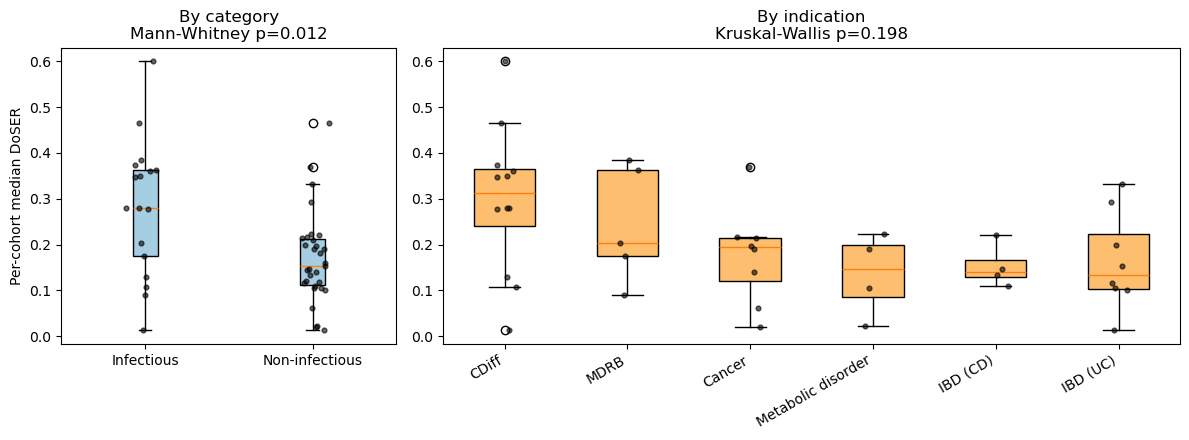

In [39]:
from itertools import combinations
from scipy import stats
from statsmodels.stats.multitest import multipletests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# ---- config ----
COHORT_COL = 'display_dataset'   # matches the keys of indication_map
DOSER_COL  = 'doser'             # adjust if named differently
MIN_COHORTS = 2

# One row per COHORT: median DoSER
cohort_doser = (
    df.dropna(subset=[DOSER_COL])
      .groupby(COHORT_COL)
      .agg(median_doser=(DOSER_COL, 'median'),
           indication=('indication_clean', 'first'),
           disease_category=('disease_category', 'first'),
           n_triads=(DOSER_COL, 'size'))
      .dropna(subset=['indication'])
)

# Guard: a cohort with >1 indication label would be silently collapsed by 'first'
multi = df.groupby(COHORT_COL)['indication_clean'].nunique()
if (multi > 1).any():
    print("WARNING: cohorts with >1 indication:", multi[multi > 1].index.tolist())

# ============================================================
# A. DoSER: infectious vs non-infectious
# ============================================================
inf    = cohort_doser.loc[cohort_doser.disease_category == 'Infectious', 'median_doser']
noninf = cohort_doser.loc[cohort_doser.disease_category == 'Non-infectious', 'median_doser']
u, p_cat = stats.mannwhitneyu(inf, noninf, alternative='two-sided')
ps = u / (len(inf) * len(noninf))   # P(infectious > non-infectious)
print("DoSER, infectious vs non-infectious (Mann-Whitney U, cohort-level):")
print(f"  Infectious     n={len(inf)}, median={inf.median():.3f}")
print(f"  Non-infectious n={len(noninf)}, median={noninf.median():.3f}")
print(f"  U={u:.1f}, p={p_cat:.4g}, P(inf > non-inf)={ps:.3f}")

# Sensitivity: drop 'Healthy Microbiome' (not a disease) from the non-infectious group
noninf_dz = cohort_doser.loc[(cohort_doser.disease_category == 'Non-infectious') &
                             (cohort_doser.indication != 'Healthy Microbiome'), 'median_doser']
u2, p2 = stats.mannwhitneyu(inf, noninf_dz, alternative='two-sided')
print(f"  Excluding Healthy Microbiome: n={len(noninf_dz)}, "
      f"median={noninf_dz.median():.3f}, U={u2:.1f}, p={p2:.4g}")

# ============================================================
# B. DoSER by indication (indications with >= MIN_COHORTS cohorts)
# ============================================================
counts = cohort_doser['indication'].value_counts()
keep = counts[counts >= MIN_COHORTS].index
d3 = cohort_doser[cohort_doser['indication'].isin(keep)]
print(f"\nIndications with >={MIN_COHORTS} cohorts: {len(keep)} "
      f"({len(d3)} of {len(cohort_doser)} cohorts)")
print("Excluded (single cohort):", counts[counts < MIN_COHORTS].index.tolist())

ind_groups = {g: s['median_doser'].values for g, s in d3.groupby('indication')}
for g, v in sorted(ind_groups.items(), key=lambda kv: -np.median(kv[1])):
    print(f"  {g}: n={len(v)}, median DoSER={np.median(v):.3f}")

h, p_ind = stats.kruskal(*ind_groups.values())
eps2 = h / (len(d3) - 1)
print(f"\nKruskal-Wallis: H({len(ind_groups)-1}) = {h:.2f}, p = {p_ind:.4g}, "
      f"epsilon^2 = {eps2:.3f}, n = {len(d3)} cohorts")

if p_ind < 0.05:
    rows = []
    for g1, g2 in combinations(ind_groups, 2):
        x, y = ind_groups[g1], ind_groups[g2]
        rows.append((g1, g2, len(x), len(y), np.median(x), np.median(y),
                     stats.mannwhitneyu(x, y, alternative='two-sided').pvalue))
    ph = pd.DataFrame(rows, columns=['group1','group2','n1','n2','median1','median2','p_raw'])
    ph['p_bh'] = multipletests(ph['p_raw'], method='fdr_bh')[1]
    print("\nPairwise Mann-Whitney (fdr_bh), exploratory:")
    print(ph.sort_values('p_bh').to_string(index=False))

# Does indication matter within each category?
for cat, sub in d3.groupby('disease_category'):
    gs = [s['median_doser'].values for _, s in sub.groupby('indication')]
    if len(gs) >= 2:
        hc, pc = stats.kruskal(*gs)
        print(f"Within {cat}: H({len(gs)-1}) = {hc:.2f}, p = {pc:.4g} ({len(gs)} indications)")

# ============================================================
# Plots
# ============================================================
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={'width_ratios': [1, 2.2]})

cats = [('Infectious', inf.values), ('Non-infectious', noninf.values)]
axes[0].boxplot([v for _, v in cats], tick_labels=[c for c, _ in cats],
                patch_artist=True, boxprops=dict(facecolor='#a6cee3'))
for i, (_, v) in enumerate(cats, 1):
    axes[0].scatter(rng.normal(i, 0.05, len(v)), v, s=12, c='k', alpha=0.6, zorder=3)
axes[0].set_ylabel('Per-cohort median DoSER')
axes[0].set_title(f'By category\nMann-Whitney p={p_cat:.3f}')

order = sorted(ind_groups, key=lambda g: -np.median(ind_groups[g]))
axes[1].boxplot([ind_groups[g] for g in order], tick_labels=order,
                patch_artist=True, boxprops=dict(facecolor='#fdbf6f'))
for i, g in enumerate(order, 1):
    axes[1].scatter(rng.normal(i, 0.05, len(ind_groups[g])), ind_groups[g],
                    s=12, c='k', alpha=0.6, zorder=3)
axes[1].set_title(f'By indication\nKruskal-Wallis p={p_ind:.3f}')
plt.setp(axes[1].get_xticklabels(), rotation=30, ha='right')
plt.tight_layout()
plt.savefig('doser_by_category_and_indication.svg', bbox_inches='tight')
plt.show()

In [40]:
# ============================================================
# C. DoSER by antibiotic exposure (3 groups), cohort-level
# ============================================================
cohort_doser['abx_group'] = cohort_doser.index.map(abx_pretreatment_map)

missing = cohort_doser[cohort_doser['abx_group'].isna()].index.tolist()
if missing:
    print("WARNING: cohorts with no ABX label (dropped):", missing)

d4 = cohort_doser.dropna(subset=['abx_group'])
abx_groups = {g: s['median_doser'].values for g, s in d4.groupby('abx_group')}

print("DoSER by antibiotic exposure (cohort-level):")
for g in ['ABX', 'ABX FMT pretreatment', 'No ABX']:
    if g in abx_groups:
        v = abx_groups[g]
        print(f"  {g}: n={len(v)}, median DoSER={np.median(v):.3f}")

h_abx, p_abx = stats.kruskal(*abx_groups.values())
eps2_abx = h_abx / (len(d4) - 1)
print(f"\nKruskal-Wallis: H({len(abx_groups)-1}) = {h_abx:.2f}, p = {p_abx:.4g}, "
      f"epsilon^2 = {eps2_abx:.3f}, n = {len(d4)} cohorts")

rows = []
for g1, g2 in combinations(abx_groups, 2):
    x, y = abx_groups[g1], abx_groups[g2]
    u = stats.mannwhitneyu(x, y, alternative='two-sided')
    rows.append((g1, g2, len(x), len(y), np.median(x), np.median(y),
                 u.statistic,
                 u.statistic / (len(x) * len(y)), u.pvalue))

ph_abx = pd.DataFrame(rows, columns=[
    'group1', 'group2', 'n1', 'n2',
    'median1', 'median2', 'U', 'P(g1>g2)', 'p_raw'
])

ph_abx['p_bh'] = multipletests(ph_abx['p_raw'], method='fdr_bh')[1]

print("\nPairwise Mann-Whitney (BH):")
print(ph_abx.to_string(index=False))

# Overlap between ABX exposure and infectious status
print("\nABX group x disease category (cohorts):")
print(pd.crosstab(d4['abx_group'], d4['disease_category']))
print("\nTherapeutic-ABX cohorts by indication:")
print(d4.loc[d4.abx_group == 'ABX', 'indication'].value_counts().to_string())

# Partial disentangling: ABX effect within each disease category
for cat, sub in d4.groupby('disease_category'):
    gs = {g: s['median_doser'].values for g, s in sub.groupby('abx_group')}
    print(f"\nWithin {cat}: " + ", ".join(f"{g} n={len(v)} med={np.median(v):.3f}"
                                          for g, v in gs.items()))
    if len(gs) >= 2 and all(len(v) >= 2 for v in gs.values()):
        hc, pc = stats.kruskal(*gs.values())
        print(f"  Kruskal-Wallis H({len(gs)-1}) = {hc:.2f}, p = {pc:.4g}")

DoSER by antibiotic exposure (cohort-level):
  ABX: n=11, median DoSER=0.279
  ABX FMT pretreatment: n=10, median DoSER=0.144
  No ABX: n=27, median DoSER=0.153

Kruskal-Wallis: H(2) = 8.00, p = 0.01828, epsilon^2 = 0.170, n = 48 cohorts

Pairwise Mann-Whitney (BH):
              group1               group2  n1  n2  median1  median2     U  P(g1>g2)    p_raw     p_bh
                 ABX ABX FMT pretreatment  11  10 0.279496 0.144285  69.0  0.627273 0.341786 0.512680
                 ABX               No ABX  11  27 0.279496 0.152778 244.0  0.821549 0.002229 0.006686
ABX FMT pretreatment               No ABX  10  27 0.144285 0.152778 153.0  0.566667 0.549491 0.549491

ABX group x disease category (cohorts):
disease_category      Infectious  Non-infectious
abx_group                                       
ABX                           10               1
ABX FMT pretreatment           6               4
No ABX                         1              26

Therapeutic-ABX cohorts by indication:

In [41]:
DATASET_COL = 'dataset'   # <- change to your study/dataset column name


def within_study_comparison(df, col, title, test_level, ref_level,
                            dataset_col=DATASET_COL, outcome='engraftment_rate', min_n=5):
    """Within-dataset Mann-Whitney U: `test_level` vs `ref_level`, one row per dataset."""
    d = df[[dataset_col, col, outcome]].dropna()
    d = d[d[col].isin([test_level, ref_level])]
    rows = []
    for ds, g in d.groupby(dataset_col):
        a = g.loc[g[col] == test_level, outcome].values
        b = g.loc[g[col] == ref_level, outcome].values
        row = dict(dataset=ds, n_test=len(a), n_ref=len(b))
        if len(a) < min_n or len(b) < min_n:
            row['note'] = f'not tested (<{min_n} in an arm)'
            rows.append(row)
            continue
        u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
        qa, qb = np.percentile(a, [25, 50, 75]), np.percentile(b, [25, 50, 75])
        row.update(
            median_test=qa[1], IQR_test=f'{qa[0]:.3f}-{qa[2]:.3f}',
            median_ref=qb[1], IQR_ref=f'{qb[0]:.3f}-{qb[2]:.3f}',
            HL_shift=np.median(np.subtract.outer(a, b)),   # Hodges-Lehmann estimate (test - ref)
            rank_biserial=2 * u / (len(a) * len(b)) - 1,   # >0: test tends higher than ref
            p=p,
        )
        rows.append(row)

    print(f'\n{title}: {test_level} vs {ref_level} (within-study, exploratory, two-sided Mann-Whitney U)')
    out = pd.DataFrame(rows)
    if 'p' in out:
        out['p'] = out['p'].map(lambda x: '' if pd.isna(x) else (f'{x:.4f}' if x >= 0.0001 else '<0.0001'))
    print(out.fillna('').to_string(index=False, float_format=lambda x: f'{x:.3f}'))
    return out


route_res = within_study_comparison(df, 'route_binary', 'DoSER by delivery route',
                                    test_level='lower', ref_level='upper')

prep_res = within_study_comparison(df, 'bowel_prep_bool', 'DoSER by bowel preparation',
                                   test_level=True, ref_level=False)

stool_res = within_study_comparison(df, 'stool_frozen_label', 'DoSER by stool type',
                                    test_level='frozen', ref_level='fresh')


DoSER by delivery route: lower vs upper (within-study, exploratory, two-sided Mann-Whitney U)
             dataset  n_test  n_ref                      note median_test    IQR_test median_ref     IQR_ref HL_shift rank_biserial      p
     BarYosephH_2020       0      7 not tested (<5 in an arm)                                                                             
            CM_FMT_L       0     22 not tested (<5 in an arm)                                                                             
        CM_IaniroFMT       6      0 not tested (<5 in an arm)                                                                             
       CM_IaniroFMT2       8      0 not tested (<5 in an arm)                                                                             
       CM_IaniroFMT3       7      0 not tested (<5 in an arm)                                                                             
       CM_IaniroFMT4       2      4 not tested (<5 in an arm)          